<a href="https://colab.research.google.com/github/a00377571/lsm-reconocimiento-mediapipe/blob/main/notebooks/Avance5_47.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Maestría en Inteligencia Artificial Aplicada**

**Curso: TC5035.10 - Proyecto Integrador**

Tecnológico de Monterrey

Profesor: Dr. Raúl Valente Ramírez Valerde

**Avance 5. Modelo Final**



*   **Estudiante:** Marco Antonio Arellano Hernández - A00377571
*   **Estudiante:** Miguel Octavio Ramírez Romero - A00828311
*   **Estudiante:** Hugo Enrique Navarro Villeda - A01796287

## **Avance 5. Modelo Final**

**Qué hace esta libreta**

1. Extrae con MediaPipe una fila de características por video del dataset propio para el proyecto (forma de ambas manos, trayectoria de las muñecas respecto a los hombros, ojos, boca y detección).
2. Realiza una exploración y visualización de los datos como parte de preprocesamiento.
3. Se realiza entrenamiento de modelos individuales frame-level (RF y MLP) y de secuencias temporales (LSTM).
4. Se realiza ensamble de tipo homogéneo y heterogéneo (Bagging de arboles, Boosting, Voting, Blending/Stacking), así como la optimización de los hiperparámetros.
5. Se comparan los modelos y se elige el modelo final de acuerdo a la métrica elegida, en este caso se toma macro-F1 como principal y se evalúa el desempeño entre modelo frame-level y secuencias temporales.
6. Ejecuta el modelo sobre videos de prueba para verificar desempeño y predicción de los modelos finales.

## Índice

1. Instalación de dependencias
2. Imports y descarga de modelos MediaPipe Tasks
3. Extracción de características holísticas
4. Recolección de datos desde video
5. Exploración y visualización
6. Entrenamiento RF y MLP (frame-a-frame)
7. Entrenamiento y evaluación LSTM (secuencias temporales)
8. Ensambles y optimización de hiperparámetros
9. Comparación final, selección del modelo y gráficos
10. Detección en tiempo real
11. Recomendaciones


## **1. Instalación de dependencias**


In [ ]:
!pip -q install opencv-python mediapipe pandas scikit-learn joblib matplotlib numpy tensorflow
!pip -q install gdown

import sys
print('Entorno listo. Python:', sys.version)



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Entorno listo. Python: 3.10.12 (main, Aug 31 2026, 10:18:17) [GCC 11.4.0]


In [ ]:
import os
import cv2
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import time
import warnings
import urllib.request
import ssl
from collections import deque, Counter

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedGroupKFold, RandomizedSearchCV)
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              BaggingClassifier, VotingClassifier, StackingClassifier)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, precision_score, recall_score,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score, ConfusionMatrixDisplay,
                             make_scorer)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential, load_model
    from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    TF_DISPONIBLE = True
except ImportError:
    TF_DISPONIBLE = False
    print('TensorFlow no instalado. Instala con: pip install tensorflow')

warnings.filterwarnings('ignore')
np.random.seed(42)

print('MediaPipe version:', mp.__version__)
print('TensorFlow disponible:', TF_DISPONIBLE)


MediaPipe version: 1.1.1
TensorFlow disponible: True


In [ ]:
# -------------------- Descarga de modelos MediaPipe Tasks con gdown --------------------

RUTA_MODELO_MANOS = 'hand_landmarker.task'
RUTA_MODELO_POSE  = 'pose_landmarker.task'
RUTA_MODELO_CARA  = 'face_landmarker.task'

IDs_GDRIVE = {
    'manos': '1B_yP56xShHBsWeMiQgjEugvuZ6-kZkal',
    'pose':  '1PwhrTrRrW_LlhGAejdXUEriiphC4Yxrr',
    'cara':  '1Q0d_gFRixpNB01eXNrTMmdpoqObOZkar',
}

for nombre, ruta in [('manos', RUTA_MODELO_MANOS), ('pose', RUTA_MODELO_POSE), ('cara', RUTA_MODELO_CARA)]:
    if os.path.exists(ruta) and os.path.getsize(ruta) > 0:
        print(f'{nombre.capitalize()}: ya existe ({ruta})')
        continue
    url = f'https://drive.google.com/uc?id={IDs_GDRIVE[nombre]}'
    print(f'Descargando {nombre}: {url}')
    try:
        gdown.download(url, ruta, quiet=False)
        if os.path.exists(ruta) and os.path.getsize(ruta) > 0:
            print(f'{nombre.capitalize()}: descargado correctamente')
        else:
            print(f'{nombre.capitalize()}: ERROR - archivo vacío o no se creó')
    except Exception as e:
        print(f'{nombre.capitalize()}: ERROR al descargar - {e}')


def crear_detectores():
    """Crea los 3 detectores: manos, pose y cara."""
    # Verificar que los archivos existen
    for ruta in [RUTA_MODELO_MANOS, RUTA_MODELO_POSE, RUTA_MODELO_CARA]:
        if not os.path.exists(ruta) or os.path.getsize(ruta) == 0:
            raise FileNotFoundError(f'No se encontró el modelo: {ruta}. Súbelo manualmente o verifica la descarga.')

    base_opts = python.BaseOptions

    manos = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(
            base_options=base_opts(model_asset_path=RUTA_MODELO_MANOS),
            running_mode=vision.RunningMode.IMAGE,
            num_hands=2,
            min_hand_detection_confidence=0.7,
            min_hand_presence_confidence=0.7,
        )
    )

    pose = vision.PoseLandmarker.create_from_options(
        vision.PoseLandmarkerOptions(
            base_options=base_opts(model_asset_path=RUTA_MODELO_POSE),
            running_mode=vision.RunningMode.IMAGE,
            min_pose_detection_confidence=0.7,
            min_pose_presence_confidence=0.7,
        )
    )

    cara = vision.FaceLandmarker.create_from_options(
        vision.FaceLandmarkerOptions(
            base_options=base_opts(model_asset_path=RUTA_MODELO_CARA),
            running_mode=vision.RunningMode.IMAGE,
            output_face_blendshapes=False,
            output_facial_transformation_matrixes=False,
            min_face_detection_confidence=0.7,
            min_face_presence_confidence=0.7,
        )
    )

    print('Detectores HandLandmarker, PoseLandmarker y FaceLandmarker creados.')
    return manos, pose, cara


Manos: ya existe (hand_landmarker.task)
Pose: ya existe (pose_landmarker.task)
Cara: ya existe (face_landmarker.task)


In [ ]:
# -------------------- Rutas y configuración --------------------
RUTA_DATOS = 'datos_lsm'
ARCHIVO_DATOS = 'landmarks_lsm.csv'
RUTA_MODELO = 'modelo_lsm.pkl'
RUTA_SCALER = 'scaler_lsm.pkl'
RUTA_ENCODER = 'encoder_lsm.pkl'
RUTA_COLUMNAS = 'columnas_lsm.pkl'
RUTA_MODELO_LSTM = 'modelo_lstm_lsm.h5'
RUTA_SCALER_LSTM = 'scaler_lstm.pkl'
RUTA_ENCODER_LSTM = 'encoder_lstm.pkl'

os.makedirs(RUTA_DATOS, exist_ok=True)

# -------------------- Clases de LSM --------------------
ALFABETO_LSM = [
    'A','B','C','D','E','F','G','H','I','J','K','L','M','N','Ñ','O','P','Q',
    'R','S','T','U','V','W','X','Y','Z',
]

PALABRAS_LSM = ['HOLA', 'GRACIAS', 'ADIOS', 'SI', 'NO', 'PORFAVOR', 'PERDON', 'NOMBRE', 'TU', 'YO']

CLASES_LSM = ALFABETO_LSM + PALABRAS_LSM
print(f'Total de clases definidas: {len(CLASES_LSM)}')
print(CLASES_LSM)


Total de clases definidas: 37
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Ñ', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'HOLA', 'GRACIAS', 'ADIOS', 'SI', 'NO', 'PORFAVOR', 'PERDON', 'NOMBRE', 'TU', 'YO']


## **2. Conceptos clave: MediaPipe Tasks y estructura EDA**

| Detector | Qué detecta | Puntos clave |
|---|---|---|
| Manos | Hasta 2 manos | 21 landmarks cada una |
| Pose | Tronco, hombros, brazos | 8 landmarks |
| Cara | Ojos, cejas, boca | 46 landmarks |

### Estructura del dataset (una línea por frame)
| Grupo | Columnas |
|---|---|
| Coordenadas manos | 63 × 2 manos |
| Distancias manos | 20 × 2 manos |
| Ángulos manos | 19 × 2 manos |
| Orientación muñeca | 2 × 2 manos |
| Posición muñeca | 3 × 2 manos |
| Pose (tronco/brazos/hombros) | 35 |
| Cara (ojos, cejas, boca) | 138 |
| Conteo | 3 |
| Etiqueta | 1 |
| **Total** | **391 columnas** |


In [ ]:
# -------------------- Extracción de características --------------------

DEDOS = {'thumb':[1,2,3,4], 'index':[5,6,7,8], 'middle':[9,10,11,12], 'ring':[13,14,15,16], 'pinky':[17,18,19,20]}
BASES_DEDOS = [1, 5, 9, 13, 17]

def angulo_entre(p1, p2, p3):
    v1 = p1 - p2; v2 = p3 - p2
    n1 = np.linalg.norm(v1); n2 = np.linalg.norm(v2)
    if n1 < 1e-6 or n2 < 1e-6: return 0.0
    cos = np.clip(np.dot(v1, v2) / (n1 * n2), -1.0, 1.0)
    return float(np.degrees(np.arccos(cos)))

def extraer_mano(landmarks_mano, prefijo):
    pts = np.array([[lm.x, lm.y, lm.z] for lm in landmarks_mano], dtype=np.float32)
    wrist = pts[0].copy()
    pts_c = pts - wrist
    escala = np.linalg.norm(pts_c, axis=1).max()
    escala = escala if escala > 0 else 1.0
    coords = (pts_c / escala).flatten()
    dist_wrist = np.linalg.norm(pts - wrist, axis=1)[1:] / escala
    angulos = []
    for nom, idxs in DEDOS.items():
        a1 = angulo_entre(pts[idxs[0]], pts[idxs[1]], pts[idxs[2]])
        a2 = angulo_entre(pts[idxs[1]], pts[idxs[2]], pts[idxs[3]])
        angulos.extend([a1, a2])
    nomes_bases = ['thumb','index','middle','ring','pinky']
    for i in range(len(BASES_DEDOS)-1):
        angulos.append(angulo_entre(pts[0], pts[BASES_DEDOS[i]], pts[BASES_DEDOS[i+1]]))
    eje = np.mean(pts[BASES_DEDOS], axis=0) - wrist
    eje = eje / (np.linalg.norm(eje) + 1e-6)
    for nom, b in zip(nomes_bases, BASES_DEDOS):
        v = pts[b] - wrist; v = v / (np.linalg.norm(v) + 1e-6)
        cos = np.clip(np.dot(v, eje), -1.0, 1.0)
        angulos.append(float(np.degrees(np.arccos(cos))))
    angulos = np.array(angulos, dtype=np.float32)
    ori = (pts[12] - wrist)[:2]
    n = np.linalg.norm(ori)
    ori = ori / n if n > 0 else np.array([0.0, 0.0], dtype=np.float32)
    vector = np.concatenate([coords, dist_wrist, angulos, ori, wrist])
    return vector

POSE_INDICES = [11, 12, 13, 14, 15, 16, 23, 24]
POSE_NOMBRES = ['hombro_izq','hombro_der','codo_izq','codo_der','muneca_izq','muneca_der','cadera_izq','cadera_der']
POSE_CONEXIONES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24)]

def extraer_pose(landmarks_pose, prefijo='p_'):
    # Normalización invariante a traslación y escala:
    #   - origen: punto medio de los hombros (landmarks 11 y 12)
    #   - escala: distancia entre hombros (11-12)
    pts = np.array([[lm.x, lm.y, lm.z] for lm in landmarks_pose], dtype=np.float32)
    pts_sel = pts[POSE_INDICES]
    centro = (pts[11] + pts[12]) / 2.0
    escala = float(np.linalg.norm(pts[11] - pts[12]))
    escala = escala if escala > 1e-6 else 1.0
    coords = ((pts_sel - centro) / escala).flatten()
    dists = np.linalg.norm(pts_sel - centro, axis=1) / escala
    angulos = [
        angulo_entre(pts[11], pts[13], pts[15]),
        angulo_entre(pts[12], pts[14], pts[16]),
        angulo_entre(pts[11], pts[12], pts[23]),
    ]
    return np.concatenate([coords, dists, np.array(angulos, dtype=np.float32)])

CARA_INDICES = [33,160,158,153,144,145,7,163, 362,385,387,380,373,374,381,263, 70,63,105,66,107, 336,296,334,293,300, 61,146,91,181,84,17,314,405,321,375,291,402,318,317,14,87,178,88,95,0]

def extraer_cara(landmarks_cara, prefijo='f_'):
    # Normalización invariante a traslación y escala:
    #   - origen: punto medio entre las comisuras externas de los ojos (33 y 263)
    #   - escala: distancia interocular (33-263)
    pts = np.array([[lm.x, lm.y, lm.z] for lm in landmarks_cara], dtype=np.float32)
    centro = (pts[33] + pts[263]) / 2.0
    escala = float(np.linalg.norm(pts[33] - pts[263]))
    escala = escala if escala > 1e-6 else 1.0
    return ((pts[CARA_INDICES] - centro) / escala).flatten()

HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(0,9),(9,10),(10,11),(11,12),(0,13),(13,14),(14,15),(0,17),(17,18),(18,19),(19,20),(5,9),(9,13),(13,17),(5,17)]


In [ ]:
# -------------------- Vector completo y columnas EDA --------------------

def vector_holistico(res_manos, res_pose, res_cara):
    partes = []
    num_manos = 0
    if res_manos.hand_landmarks:
        num_manos = min(len(res_manos.hand_landmarks), 2)
        for i in range(num_manos):
            partes.append(extraer_mano(res_manos.hand_landmarks[i], 'r_' if i==0 else 'l_'))
    while num_manos < 2:
        partes.append(np.zeros(107, dtype=np.float32)); num_manos += 1

    num_pose = 0
    if res_pose.pose_landmarks and len(res_pose.pose_landmarks) > 0:
        num_pose = 1
        partes.append(extraer_pose(res_pose.pose_landmarks[0], 'p_'))
    else:
        partes.append(np.zeros(35, dtype=np.float32))

    num_cara = 0
    if res_cara.face_landmarks:
        num_cara = 1
        partes.append(extraer_cara(res_cara.face_landmarks[0], 'f_'))
    else:
        partes.append(np.zeros(len(CARA_INDICES)*3, dtype=np.float32))

    return np.concatenate(partes), num_manos, num_pose, num_cara

def vector_a_fila(vector, num_manos, num_pose, num_cara, etiqueta):
    return np.concatenate([vector, [float(num_manos)], [float(num_pose)], [float(num_cara)], [etiqueta]])

def construir_nombres_columnas():
    columnas = []
    for prefijo in ['r_', 'l_']:
        for i in range(21): columnas += [f'{prefijo}x{i}', f'{prefijo}y{i}', f'{prefijo}z{i}']
        for i in range(1, 21): columnas.append(f'{prefijo}dist_{i}')
        for nom in DEDOS:
            columnas += [f'{prefijo}angle_{nom}_mcp', f'{prefijo}angle_{nom}_pip']
        nomes_bases = ['thumb','index','middle','ring','pinky']
        for i in range(4): columnas.append(f'{prefijo}angle_spread_{nomes_bases[i]}_{nomes_bases[i+1]}')
        for nom in nomes_bases: columnas.append(f'{prefijo}angle_{nom}_axis')
        columnas += [f'{prefijo}hand_ori_x', f'{prefijo}hand_ori_y']
        columnas += [f'{prefijo}wrist_x', f'{prefijo}wrist_y', f'{prefijo}wrist_z']
    for nom in POSE_NOMBRES: columnas += [f'p_x_{nom}', f'p_y_{nom}', f'p_z_{nom}']
    for i in range(len(POSE_INDICES)): columnas.append(f'p_dist_{i}')
    columnas += ['p_angle_brazo_izq','p_angle_brazo_der','p_angle_hombros']
    for idx in CARA_INDICES: columnas += [f'f_x{idx}', f'f_y{idx}', f'f_z{idx}']
    columnas += ['num_manos','num_pose','num_cara','label']
    return columnas

COLUMNAS_EDA = construir_nombres_columnas()
print(f'Total de columnas EDA: {len(COLUMNAS_EDA)}')


Total de columnas EDA: 391


In [ ]:
# -------------------- Dibujo manual --------------------

def dibujar_mano(frame, landmarks, conexiones, color_punto=(0,255,0), color_linea=(255,0,0)):
    alto, ancho = frame.shape[:2]
    pts = [(int(lm.x*ancho), int(lm.y*alto)) for lm in landmarks]
    for x,y in pts: cv2.circle(frame,(x,y),3,color_punto,-1)
    for ini,fin in conexiones:
        if ini < len(pts) and fin < len(pts): cv2.line(frame, pts[ini], pts[fin], color_linea, 2)

def dibujar_pose(frame, landmarks_pose, conexiones):
    alto, ancho = frame.shape[:2]
    pts = {}
    for idx in POSE_INDICES:
        lm = landmarks_pose[idx]
        pts[idx] = (int(lm.x*ancho), int(lm.y*alto))
        cv2.circle(frame, pts[idx], 5, (0,255,255), -1)
    for ini,fin in conexiones:
        if ini in pts and fin in pts: cv2.line(frame, pts[ini], pts[fin], (255,255,0), 2)

def dibujar_cara(frame, landmarks_cara, indices):
    alto, ancho = frame.shape[:2]
    for idx in indices:
        lm = landmarks_cara[idx]
        cv2.circle(frame, (int(lm.x*ancho), int(lm.y*alto)), 2, (0,0,255), -1)

def dibujar_holistico(frame, res_manos, res_pose, res_cara):
    if res_manos.hand_landmarks:
        for mano in res_manos.hand_landmarks: dibujar_mano(frame, mano, HAND_CONNECTIONS)
    if res_pose.pose_landmarks and len(res_pose.pose_landmarks) > 0:
        dibujar_pose(frame, res_pose.pose_landmarks[0], POSE_CONEXIONES)
    if res_cara.face_landmarks:
        dibujar_cara(frame, res_cara.face_landmarks[0], CARA_INDICES)
    return frame


## **3. Recolección de datos desde video**


In [ ]:
# -------------------- Captura de datos para un solo video --------------------
def capturar_datos_video(ruta_video, etiqueta, salida_csv, max_frames=None,
                         cada_n_frames=1, detectores=None, usar_webcam=False,
                         video_id=None, mostrar=True):
    """Extrae landmarks de un video/webcam y guarda un CSV.

    mostrar=False permite procesar en lote sin abrir ventanas de OpenCV.
    """
    if detectores is None: detectores = crear_detectores()
    det_manos, det_pose, det_cara = detectores
    if video_id is None:
        if usar_webcam:
            video_id = time.strftime('webcam_%Y%m%d_%H%M%S')
        else:
            video_id = os.path.splitext(os.path.basename(ruta_video))[0]
    cap = cv2.VideoCapture(0 if usar_webcam else ruta_video)
    if not cap.isOpened(): raise RuntimeError('No se pudo abrir el video/webcam')
    filas, frame_idx, guardados = [], 0, 0
    while True:
        ret, frame = cap.read()
        if not ret: break
        frame_idx += 1
        if frame_idx % cada_n_frames != 0: continue
        imagen_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_mp = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagen_rgb)
        res_manos = det_manos.detect(image_mp)
        res_pose  = det_pose.detect(image_mp)
        res_cara  = det_cara.detect(image_mp)
        vector, num_manos, num_pose, num_cara = vector_holistico(res_manos, res_pose, res_cara)

        if mostrar:
            dibujar_holistico(frame, res_manos, res_pose, res_cara)
            estado = f'M:{num_manos} P:{num_pose} C:{num_cara}'
            cv2.putText(frame, f'Clase: {etiqueta} | {estado}', (10,30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2)
            cv2.putText(frame, f'Guardados: {guardados}', (10,70),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2)
            cv2.imshow('Captura LSM Tasks - Q para salir', frame)

        fila = vector_a_fila(vector, num_manos, num_pose, num_cara, etiqueta)
        filas.append(fila); guardados += 1

        if mostrar and (cv2.waitKey(1) & 0xFF == ord('q')): break
        if max_frames and guardados >= max_frames: break

    cap.release()
    if mostrar: cv2.destroyAllWindows()

    if not filas:
        print(f'[AVISO] No se detectaron frames en {ruta_video}; no se guarda CSV')
        return pd.DataFrame(columns=COLUMNAS_EDA + ['video_id'])

    df = pd.DataFrame(filas, columns=COLUMNAS_EDA)
    df['video_id'] = video_id
    df.to_csv(salida_csv, index=False)
    print(f'Guardados {guardados} frames en {salida_csv} (video_id={video_id})')
    return df

# Ejemplos de uso:
#df_a = capturar_datos_video('videos_test/hola100.mp4', 'hola', 'datos_lsm/hola100.csv')
#df_a = capturar_datos_video('videos_lsm/agua/agua01.mp4', 'agua', 'datos_lsm/agua01.csv')
# df_webcam = capturar_datos_video(None, 'hola', 'datos_lsm/hola_webcam.csv', usar_webcam=True, max_frames=400)

In [ ]:
# -------------------- Captura masiva desde videos_lsm --------------------
def capturar_datos_carpeta_videos(carpeta_videos='videos_lsm',
                                  carpeta_salida=RUTA_DATOS,
                                  cada_n_frames=1,
                                  max_frames=None,
                                  max_videos_por_clase=None,
                                  sobrescribir=False,
                                  mostrar=False,
                                  clases=None,
                                  excluir_videos=None):
    """Procesa videos_lsm/<clase>/*.mp4 y guarda un CSV por video.

    - La etiqueta se toma del nombre de la carpeta (agua, amigo, ...).
    - video_id = nombre del archivo sin extensión (agua01, agua02, ...).
    - Un CSV por video: unir_datos() los trata como sesiones distintas.
    - Si sobrescribir=False, omite los videos que ya tienen CSV.
    - mostrar=True abre una ventana por video (útil para revisar).
    - excluir_videos permite reservar videos para prueba, por ejemplo:
      ['agua03', 'amigo03', 'comer04', 'gracias02', 'hola04', 'necesitar04', 'trabajo03'].
    """
    os.makedirs(carpeta_salida, exist_ok=True)
    detectores = crear_detectores()
    extensiones = ('.mp4', '.avi', '.mov', '.mkv', '.webm')
    excluir = {str(x).lower() for x in (excluir_videos or [])}

    if clases is None:
        clases = sorted(d for d in os.listdir(carpeta_videos)
                        if os.path.isdir(os.path.join(carpeta_videos, d)))

    resumen = []
    for clase in clases:
        dir_clase = os.path.join(carpeta_videos, clase)
        if not os.path.isdir(dir_clase):
            print(f'[AVISO] No existe la carpeta {dir_clase}')
            continue

        videos = sorted(f for f in os.listdir(dir_clase)
                        if f.lower().endswith(extensiones))
        if max_videos_por_clase:
            videos = videos[:max_videos_por_clase]
        if not videos:
            print(f'[AVISO] Sin videos en {dir_clase}')
            continue

        print(f'\n=== {clase}: {len(videos)} videos ===')
        for k, video in enumerate(videos, 1):
            video_id = os.path.splitext(video)[0]
            # Evita colisiones si dos carpetas tienen archivos con el mismo nombre.
            if not video_id.lower().startswith(clase.lower()):
                video_id = f'{clase}_{video_id}'

            if video_id.lower() in excluir or video.lower() in excluir:
                print(f'[{k}/{len(videos)}] OMITIDO (excluido): {video}')
                resumen.append({'clase': clase, 'video': video, 'video_id': video_id,
                                'frames': 0, 'estado': 'excluido'})
                continue

            salida = os.path.join(carpeta_salida, f'{video_id}.csv')
            if os.path.exists(salida) and not sobrescribir:
                print(f'[{k}/{len(videos)}] OMITIDO (ya existe): {salida}')
                resumen.append({'clase': clase, 'video': video, 'video_id': video_id,
                                'frames': None, 'estado': 'ya existe'})
                continue

            print(f'[{k}/{len(videos)}] Procesando {video} -> {salida}', flush=True)
            try:
                df = capturar_datos_video(
                    ruta_video=os.path.join(dir_clase, video),
                    etiqueta=clase,
                    salida_csv=salida,
                    max_frames=max_frames,
                    cada_n_frames=cada_n_frames,
                    detectores=detectores,
                    mostrar=False,
                    video_id=video_id)
                estado = 'ok' if len(df) else 'sin frames'
                n = len(df)
            except Exception as e:
                print(f'  ERROR: {e}')
                estado, n = f'error: {e}', 0
            resumen.append({'clase': clase, 'video': video, 'video_id': video_id,
                            'frames': n, 'estado': estado})

    resumen_df = pd.DataFrame(resumen)
    print('\n=== Resumen de captura ===')
    if len(resumen_df):
        print(resumen_df.groupby(['clase', 'estado']).size().to_string())
        print(f'Frames totales: {resumen_df["frames"].fillna(0).sum():.0f}')
    return resumen_df

# Uso:
resumen = capturar_datos_carpeta_videos()                         # todos los videos
# resumen = capturar_datos_carpeta_videos(cada_n_frames=2)          # más rápido
# resumen = capturar_datos_carpeta_videos(clases=['agua', 'amigo']) # solo algunas clases
# resumen = capturar_datos_carpeta_videos(max_videos_por_clase=2)   # prueba rápida
# resumen = capturar_datos_carpeta_videos(
#     excluir_videos=['agua03','amigo03','comer04','gracias02',
#                     'hola04','necesitar04','trabajo03']
# )  # reserva esos videos para prueba

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793658781.416016  103288 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793658781.439364  103289 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793658781.533193  103296 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793658781.578584  103296 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793658781.582133  103299 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1793658781.596657  103301 inference_feedback_manager.cc:121] Feedback mana

Detectores HandLandmarker, PoseLandmarker y FaceLandmarker creados.

=== agua: 15 videos ===
[1/15] OMITIDO (ya existe): datos_lsm/agua01.csv
[2/15] OMITIDO (ya existe): datos_lsm/agua02.csv
[3/15] OMITIDO (ya existe): datos_lsm/agua03.csv
[4/15] OMITIDO (ya existe): datos_lsm/agua04.csv
[5/15] OMITIDO (ya existe): datos_lsm/agua05.csv
[6/15] OMITIDO (ya existe): datos_lsm/agua06.csv
[7/15] OMITIDO (ya existe): datos_lsm/agua07.csv
[8/15] OMITIDO (ya existe): datos_lsm/agua08.csv
[9/15] OMITIDO (ya existe): datos_lsm/agua09.csv
[10/15] OMITIDO (ya existe): datos_lsm/agua10.csv
[11/15] OMITIDO (ya existe): datos_lsm/agua11.csv
[12/15] OMITIDO (ya existe): datos_lsm/agua12.csv
[13/15] OMITIDO (ya existe): datos_lsm/agua13.csv
[14/15] OMITIDO (ya existe): datos_lsm/agua14.csv
[15/15] OMITIDO (ya existe): datos_lsm/agua15.csv

=== amigo: 15 videos ===
[1/15] OMITIDO (ya existe): datos_lsm/amigo01.csv
[2/15] OMITIDO (ya existe): datos_lsm/amigo02.csv
[3/15] OMITIDO (ya existe): datos_lsm/am

In [ ]:
def unir_datos(carpeta=RUTA_DATOS, salida=ARCHIVO_DATOS):
    archivos = [f for f in os.listdir(carpeta) if f.endswith('.csv')]
    if not archivos: raise FileNotFoundError(f'No se encontraron CSV en {carpeta}')
    partes = []
    for archivo in archivos:
        df_parcial = pd.read_csv(os.path.join(carpeta, archivo))
        faltantes = [c for c in COLUMNAS_EDA if c not in df_parcial.columns]
        for c in faltantes: df_parcial[c] = 0.0
        base = os.path.splitext(os.path.basename(archivo))[0]
        if 'video_id' not in df_parcial.columns or df_parcial['video_id'].isna().all():
            etiquetas = df_parcial['label'].values
            cambios = np.r_[True, etiquetas[1:] != etiquetas[:-1]]
            runs = np.cumsum(cambios)
            df_parcial['video_id'] = [f'{base}_r{r}' for r in runs]
        else:
            df_parcial['video_id'] = df_parcial['video_id'].fillna(base).astype(str)
        partes.append(df_parcial[COLUMNAS_EDA + ['video_id']])
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(salida, index=False)
    print(f'Total unido: {len(df)} frames en {salida}')
    print(f'Videos únicos: {df["video_id"].nunique()}')
    print(df['label'].value_counts().sort_index())
    return df

# Ejecutar solo si ya tienes datos recolectados:
df_total = unir_datos()


## **4. Exploración y visualización de los datos**


In [ ]:
# -------------------- Eliminacion de etiquetas con pocos datos --------------------
def eliminar_etiquetas_pocos_datos(df):
    """Elimina del DataFrame las etiquetas con pocos datos."""
    etiquetas_pocos_datos = ['ayuda', 'casa', 'querer']
    df_total = df[~df["label"].isin(etiquetas_pocos_datos)].reset_index(drop=True)
    print(f'Etiquetas eliminadas por pocos datos: {etiquetas_pocos_datos}')
    print(f'Frames restantes: {len(df_total)} | Clases: {sorted(df_total["label"].unique())}')
    return df_total

Etiquetas eliminadas por pocos datos: ['ayuda', 'casa', 'querer']
Frames restantes: 8814 | Clases: ['agua', 'amigo', 'comer', 'gracias', 'hola', 'necesitar', 'trabajo']
Datos cargados: 8814 frames
label
agua         1251
amigo        1256
comer        1261
gracias      1491
hola         1359
necesitar    1052
trabajo      1144
Name: count, dtype: int64


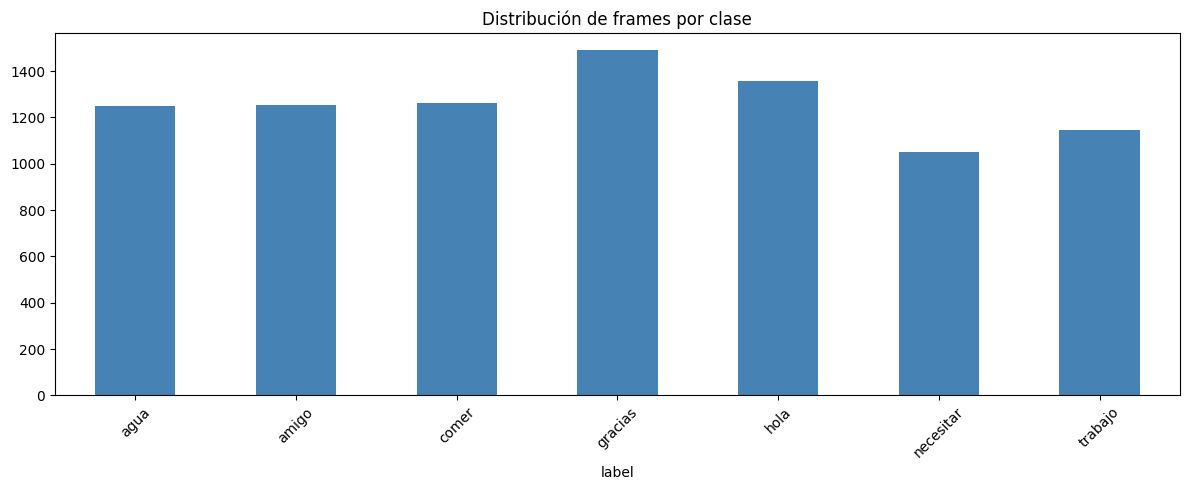

In [ ]:
if not os.path.exists(ARCHIVO_DATOS) or os.path.getsize(ARCHIVO_DATOS) == 0:
    print('Generando dataset sintético...')
    np.random.seed(42)
    filas = []
    videos_sint = []
    for c in CLASES_LSM[:10]:
        for i in range(200):
            filas.append(vector_a_fila(np.random.normal(0, 0.3, len(COLUMNAS_EDA)-4), 1, 1, 1, c))
            videos_sint.append(f'sint_{c}_{i//20}')
    df_sint = pd.DataFrame(filas, columns=COLUMNAS_EDA)
    df_sint['video_id'] = videos_sint
    df_sint.to_csv(ARCHIVO_DATOS, index=False)
    df_total = df_sint
    print(f'Dataset de ejemplo: {len(df_sint)} frames')
else:
    df_total = pd.read_csv(ARCHIVO_DATOS)
    if 'video_id' not in df_total.columns:
        df_total['video_id'] = 'sin_video'
    df_total = df_total[COLUMNAS_EDA + ['video_id']]
    df_total = eliminar_etiquetas_pocos_datos(df_total)
    print(f'Datos cargados: {len(df_total)} frames')

# Fallback: si no hay suficientes grupos, crear video_id artificiales por bloques.
if df_total['video_id'].nunique() < 5:
    df_total['video_id'] = ((df_total.groupby('label').cumcount() // 50).astype(str)
                            + '_' + df_total['label'].astype(str))
    print('Aviso: se generaron video_id artificiales por bloques de 50 frames.')

print(df_total['label'].value_counts().sort_index())
df_total['label'].value_counts().sort_index().plot(kind='bar', color='steelblue', figsize=(12,5))
plt.title('Distribución de frames por clase'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()


In [ ]:
# -------------------- Preprocesamiento con split agrupado por video --------------------
feature_cols = [c for c in COLUMNAS_EDA if c not in ('num_manos','num_pose','num_cara','label')]
X = df_total[feature_cols].values.astype(np.float32)
y = df_total['label'].values
le = LabelEncoder(); y_enc = le.fit_transform(y)
grupos = df_total['video_id'].values

# Split agrupado: ningún video aparece a la vez en train y test.
# Se elige el fold que contiene todas las clases en test (si existe).
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx = test_idx = None
fold_elegido = None
for fold, (tr, te) in enumerate(sgkf.split(X, y_enc, groups=grupos)):
    if set(np.unique(y_enc[te])) == set(range(len(le.classes_))):
        train_idx, test_idx, fold_elegido = tr, te, fold
        break
if train_idx is None:
    # Fallback: usar el último fold; las métricas se calculan con labels completos.
    train_idx, test_idx = tr, te
    fold_elegido = fold
    print('Aviso: ningún fold contiene todas las clases; se usa el último fold.')

df_train = df_total.iloc[train_idx].reset_index(drop=True)
df_test = df_total.iloc[test_idx].reset_index(drop=True)
X_train = X[train_idx]; X_test = X[test_idx]
y_train = y_enc[train_idx]; y_test = y_enc[test_idx]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f'Fold elegido: {fold_elegido}')
print(f'Entrenamiento: {X_train_s.shape} | Prueba: {X_test_s.shape}')
print(f'Videos train: {df_train["video_id"].nunique()} | test: {df_test["video_id"].nunique()}')
print(f'Clases train: {len(np.unique(y_train))}/{len(le.classes_)} | test: {len(np.unique(y_test))}/{len(le.classes_)}')
print(f'Clases: {list(le.classes_)} | Features: {X_train_s.shape[1]}')


Fold elegido: 0
Entrenamiento: (7239, 387) | Prueba: (1575, 387)
Videos train: 84 | test: 21
Clases train: 7/7 | test: 7/7
Clases: ['agua', 'amigo', 'comer', 'gracias', 'hola', 'necesitar', 'trabajo'] | Features: 387


## **5. Entrenamiento RF y MLP (frame-a-frame)**


In [ ]:
# -------------------- Optimización de hiperparámetros (RF y MLP) --------------------
# Validación cruzada agrupada por video para evitar fuga de frames del mismo video.
# Se usan 2 folds y un número moderado de candidatos para que el notebook sea
# ejecutable en Colab. Si se dispone de más tiempo, aumentar n_splits y n_iter.
cv_tuning = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)
grupos_train = df_train['video_id'].values
# Scorer directo: evita el pos_label de make_scorer cuando un fold no contiene todas las clases.
def scorer_f1_macro(estimator, X, y):
    y_pred = estimator.predict(X)
    return f1_score(y, y_pred, average='macro', zero_division=0)

# Modelos base de la fase anterior (sin tunear), para comparar
modelo_rf_base = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                        random_state=42, n_jobs=-1)
modelo_mlp_base = MLPClassifier(hidden_layer_sizes=(128,64), early_stopping=True,
                                random_state=42)

t0 = time.perf_counter(); modelo_rf_base.fit(X_train_s, y_train); t_rf_base = time.perf_counter() - t0
t0 = time.perf_counter(); modelo_mlp_base.fit(X_train_s, y_train); t_mlp_base = time.perf_counter() - t0

# Espacios de búsqueda moderados
param_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', None],
}
param_mlp = {
    'hidden_layer_sizes': [(64,), (128,), (128,64), (256,128)],
    'alpha': [1e-4, 1e-3, 1e-2],
    'learning_rate_init': [1e-3, 5e-4],
    'activation': ['relu', 'tanh'],
}

busqueda_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=param_rf, n_iter=8, scoring=scorer_f1_macro,
    cv=cv_tuning, random_state=42, n_jobs=-1, verbose=1)
busqueda_mlp = RandomizedSearchCV(
    MLPClassifier(early_stopping=True, random_state=42),
    param_distributions=param_mlp, n_iter=6, scoring=scorer_f1_macro,
    cv=cv_tuning, random_state=42, n_jobs=-1, verbose=1)

t0 = time.perf_counter(); busqueda_rf.fit(X_train_s, y_train, groups=grupos_train); t_rf_tune = time.perf_counter() - t0
t0 = time.perf_counter(); busqueda_mlp.fit(X_train_s, y_train, groups=grupos_train); t_mlp_tune = time.perf_counter() - t0

modelo_rf = busqueda_rf.best_estimator_
modelo_mlp = busqueda_mlp.best_estimator_
print('Mejores hiperparámetros RF:', busqueda_rf.best_params_)
print('Mejores hiperparámetros MLP:', busqueda_mlp.best_params_)
print(f'Mejor macro-F1 CV RF: {busqueda_rf.best_score_:.4f} | MLP: {busqueda_mlp.best_score_:.4f}')

# Tiempo total para obtener cada modelo tuneado (búsqueda + refit final)
tiempos_individuales = {
    'RF (base)': t_rf_base,
    'MLP (base)': t_mlp_base,
    'RF (tuned)': t_rf_tune + busqueda_rf.refit_time_,
    'MLP (tuned)': t_mlp_tune + busqueda_mlp.refit_time_,
}

# Modelo individual final de esta fase (mejor macro-F1 en CV)
if busqueda_rf.best_score_ >= busqueda_mlp.best_score_:
    modelo_final = modelo_rf
    nombre_final_individual = 'RF (tuned)'
else:
    modelo_final = modelo_mlp
    nombre_final_individual = 'MLP (tuned)'

joblib.dump(modelo_final, RUTA_MODELO)
joblib.dump(scaler, RUTA_SCALER)
joblib.dump(le, RUTA_ENCODER)
joblib.dump(COLUMNAS_EDA, RUTA_COLUMNAS)
print(f'Modelo individual guardado: {RUTA_MODELO} ({nombre_final_individual})')


Fitting 2 folds for each of 8 candidates, totalling 16 fits
Fitting 2 folds for each of 6 candidates, totalling 12 fits
Mejores hiperparámetros RF: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}
Mejores hiperparámetros MLP: {'learning_rate_init': 0.0005, 'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'activation': 'tanh'}
Mejor macro-F1 CV RF: 0.7366 | MLP: 0.7533
Modelo individual guardado: modelo_lsm.pkl (MLP (tuned))


## **6. Evaluación del modelo (frame-a-frame)**


Modelo individual: MLP (tuned)
Accuracy: 0.8851 | Macro-F1: 0.8483
              precision    recall  f1-score   support

        agua       0.99      0.97      0.98       275
       amigo       0.61      0.83      0.70       207
       comer       0.97      0.93      0.95       199
     gracias       0.86      0.68      0.76        28
        hola       1.00      0.99      1.00       458
   necesitar       0.88      0.99      0.93       182
     trabajo       0.76      0.52      0.62       226

    accuracy                           0.89      1575
   macro avg       0.87      0.84      0.85      1575
weighted avg       0.89      0.89      0.88      1575



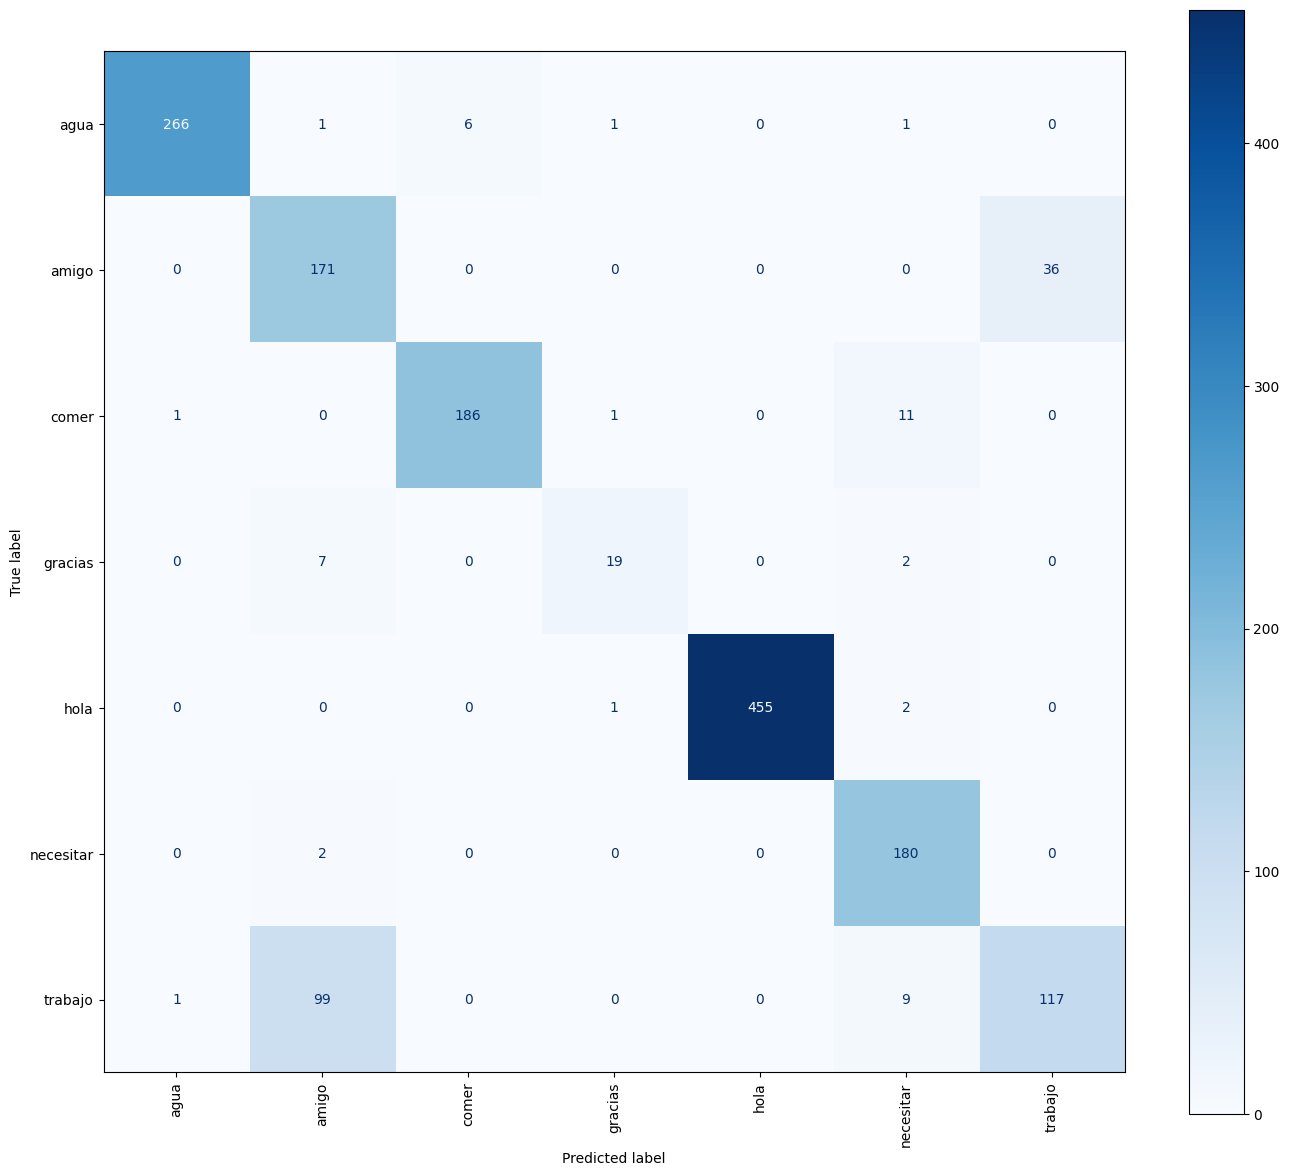

In [ ]:
y_pred = modelo_final.predict(X_test_s)
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro',
                    labels=np.arange(len(le.classes_)), zero_division=0)
print(f'Modelo individual: {nombre_final_individual}')
print(f'Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f}')
print(classification_report(y_test, y_pred,
                            labels=np.arange(len(le.classes_)),
                            target_names=[str(c) for c in le.classes_],
                            zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(le.classes_)))
fig, ax = plt.subplots(figsize=(14,12))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap='Blues', values_format='d')
plt.xticks(rotation=90); plt.tight_layout(); plt.show()


## **7. Entrenamiento y evaluación LSTM (secuencias temporales)**


In [ ]:
# -------------------- Clase LSTM integrada --------------------
class LSTMModeloLSM:
    def __init__(self, ventana=30, num_clases=None, num_features=None,
                 modelo_ruta='modelo_lstm_lsm.h5', scaler_ruta='scaler_lstm.pkl', encoder_ruta='encoder_lstm.pkl'):
        self.ventana=ventana; self.num_clases=num_clases; self.num_features=num_features
        self.modelo_ruta=modelo_ruta; self.scaler_ruta=scaler_ruta; self.encoder_ruta=encoder_ruta
        self.modelo=None; self.scaler=None; self.le=None

    def crear_secuencias(self, X, y, ventana=None):
        v = ventana or self.ventana
        Xs, ys = [], []
        for i in range(len(X)-v+1):
            Xs.append(X[i:i+v]); ys.append(y[i+v-1])
        return np.array(Xs, dtype=np.float32), np.array(ys)

    def construir_modelo(self, num_clases=None, num_features=None, ventana=None, verbose=1):
        if not TF_DISPONIBLE: raise ImportError('TensorFlow no disponible')
        nc = num_clases or self.num_clases; nf = num_features or self.num_features; v = ventana or self.ventana
        m = Sequential([
            LSTM(64, return_sequences=True, input_shape=(v, nf)), BatchNormalization(), Dropout(0.3),
            LSTM(32, return_sequences=False), BatchNormalization(), Dropout(0.3),
            Dense(32, activation='relu'), Dropout(0.2), Dense(nc, activation='softmax')])
        m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.modelo=m; self.num_clases=nc; self.num_features=nf; self.ventana=v
        if verbose: print('Modelo LSTM construido'); m.summary()

    def entrenar(self, X_train, y_train, X_val=None, y_val=None, epochs=50, batch_size=32, paciencia=10, verbose=0):
        cb = [EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True, verbose=0),
              ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=0)]
        val = (X_val, y_val) if X_val is not None else None
        self.historial = self.modelo.fit(X_train, y_train, validation_data=val, epochs=epochs,
                                         batch_size=batch_size, callbacks=cb, verbose=verbose)

    def evaluar(self, X_test, y_test, nombres_clases=None):
        y_pred_proba = self.modelo.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)
        acc = accuracy_score(y_test, y_pred)
        labels = np.arange(len(nombres_clases)) if nombres_clases is not None else None
        print(f'Accuracy LSTM: {acc:.4f}')
        print(classification_report(y_test, y_pred, labels=labels,
                                    target_names=[str(c) for c in nombres_clases] if nombres_clases else None,
                                    zero_division=0))
        return {'accuracy': acc, 'y_pred': y_pred, 'y_proba': y_pred_proba}

    def predecir_secuencia(self, secuencia):
        secuencia = np.array(secuencia, dtype=np.float32)
        if secuencia.ndim == 2: secuencia = secuencia.reshape(1, *secuencia.shape)
        proba = self.modelo.predict(secuencia, verbose=0)[0]
        idx = np.argmax(proba); return self.le.inverse_transform([idx])[0], float(proba[idx])

    def guardar(self):
        self.modelo.save(self.modelo_ruta); joblib.dump(self.scaler, self.scaler_ruta); joblib.dump(self.le, self.encoder_ruta)

    def cargar(self):
        self.modelo = load_model(self.modelo_ruta)
        self.scaler = joblib.load(self.scaler_ruta); self.le = joblib.load(self.encoder_ruta)
        self.num_clases = len(self.le.classes_); self.num_features = self.modelo.input_shape[2]; self.ventana = self.modelo.input_shape[1]


In [ ]:
# -------------------- Preparar secuencias LSTM por video --------------------
if TF_DISPONIBLE:
    VENTANA_LSTM = 30
    PASO_LSTM = 1

    def crear_secuencias_por_video(df, scaler, ventana=VENTANA_LSTM, paso=PASO_LSTM):
        # Crea ventanas sin cruzar fronteras de video.
        Xs, ys = [], []
        for vid, grupo in df.groupby('video_id', sort=False):
            Xg = scaler.transform(grupo[feature_cols].values.astype(np.float32))
            yg = le.transform(grupo['label'].values)
            for i in range(0, len(Xg) - ventana + 1, paso):
                Xs.append(Xg[i:i+ventana]); ys.append(yg[i+ventana-1])
        if not Xs:
            return np.empty((0, ventana, len(feature_cols)), dtype=np.float32), np.empty((0,), dtype=int)
        return np.array(Xs, dtype=np.float32), np.array(ys, dtype=int)

    X_train_seq, y_train_seq = crear_secuencias_por_video(df_train, scaler)
    X_test_seq, y_test_seq = crear_secuencias_por_video(df_test, scaler)
    print(f'Secuencias train: {X_train_seq.shape} | test: {X_test_seq.shape}')


Secuencias train: (4807, 30, 387) | test: (975, 30, 387)


In [ ]:
if TF_DISPONIBLE:
    lstm = LSTMModeloLSM(ventana=VENTANA_LSTM, num_clases=len(le.classes_),
                         num_features=X_train_seq.shape[2])
    lstm.scaler = scaler
    lstm.le = le
    lstm.construir_modelo(verbose=1)

    # Validación por video (no por ventana) para EarlyStopping
    conteo = df_train.groupby('video_id').size()
    videos_validos = conteo[conteo >= VENTANA_LSTM].index
    videos_info = (df_train[df_train['video_id'].isin(videos_validos)]
                   .groupby('video_id')['label'].first().reset_index())
    if len(videos_info) >= 2:
        v_fit, v_val = train_test_split(videos_info['video_id'].values,
                                        test_size=0.15, random_state=42)
        df_fit = df_train[df_train['video_id'].isin(v_fit)]
        df_val = df_train[df_train['video_id'].isin(v_val)]
        X_fit, y_fit = crear_secuencias_por_video(df_fit, scaler)
        X_val, y_val = crear_secuencias_por_video(df_val, scaler)
    else:
        X_fit, y_fit = X_train_seq, y_train_seq
        X_val, y_val = None, None
    if X_val is None or len(X_val) == 0:
        X_fit, X_val, y_fit, y_val = train_test_split(X_fit, y_fit, test_size=0.1, random_state=42)

    t0 = time.perf_counter()
    lstm.entrenar(X_fit, y_fit, X_val, y_val, epochs=50, batch_size=32,
                  paciencia=10, verbose=2)
    tiempo_lstm = time.perf_counter() - t0
    lstm.guardar()
    print(f'Tiempo entrenamiento LSTM: {tiempo_lstm:.2f} s')


Modelo LSTM construido


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │       115,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,799 (507.03 KB)

 Trainable params: 129,607 (506.28 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/50


W0000 00:00:1793661254.405595  101455 cpu_allocator_impl.cc:82] Allocation of 185945760 exceeds 10% of free system memory.


126/126 - 8s - 64ms/step - accuracy: 0.7710 - loss: 0.7457 - val_accuracy: 0.8369 - val_loss: 0.7328 - learning_rate: 0.0010
Epoch 2/50
126/126 - 3s - 21ms/step - accuracy: 0.9630 - loss: 0.1776 - val_accuracy: 0.9664 - val_loss: 0.1243 - learning_rate: 0.0010
Epoch 3/50
126/126 - 3s - 23ms/step - accuracy: 0.9835 - loss: 0.0995 - val_accuracy: 0.8593 - val_loss: 0.5792 - learning_rate: 0.0010
Epoch 4/50
126/126 - 4s - 30ms/step - accuracy: 0.9825 - loss: 0.0743 - val_accuracy: 0.8443 - val_loss: 0.6203 - learning_rate: 0.0010
Epoch 5/50
126/126 - 3s - 23ms/step - accuracy: 0.9918 - loss: 0.0432 - val_accuracy: 0.8904 - val_loss: 0.4584 - learning_rate: 0.0010
Epoch 6/50
126/126 - 3s - 24ms/step - accuracy: 0.9873 - loss: 0.0599 - val_accuracy: 0.9265 - val_loss: 0.3653 - learning_rate: 0.0010
Epoch 7/50
126/126 - 3s - 25ms/step - accuracy: 0.9793 - loss: 0.0766 - val_accuracy: 0.8655 - val_loss: 0.7936 - learning_rate: 0.0010
Epoch 8/50
126/126 - 3s - 23ms/step - accuracy: 0.9943 - lo

Tiempo entrenamiento LSTM: 41.84 s


In [ ]:
if TF_DISPONIBLE:
    res_lstm = lstm.evaluar(X_test_seq, y_test_seq, nombres_clases=[str(c) for c in le.classes_])

    # Predicción frame-level: se asigna a cada frame la predicción de la ventana que termina en él.
    def predecir_lstm_frames(df, lstm, scaler, ventana=VENTANA_LSTM):
        Xw, yw, idxw = [], [], []
        for vid, grupo in df.groupby('video_id', sort=False):
            Xg = scaler.transform(grupo[feature_cols].values.astype(np.float32))
            yg = le.transform(grupo['label'].values)
            for i in range(0, len(Xg) - ventana + 1):
                Xw.append(Xg[i:i+ventana])
                yw.append(yg[i+ventana-1])
                idxw.append(grupo.index[i+ventana-1])
        Xw = np.array(Xw, dtype=np.float32)
        t0 = time.perf_counter()
        proba = lstm.modelo.predict(Xw, verbose=0)
        t_inf = time.perf_counter() - t0
        pred = np.argmax(proba, axis=1)
        tiempo_inferencia_lstm_ms = 1000 * t_inf / max(len(Xw), 1)
        return np.array(yw), pred, np.array(idxw), proba, tiempo_inferencia_lstm_ms

    y_lstm_frame, pred_lstm_frame, idx_lstm_frame, proba_lstm_frame, tiempo_inferencia_lstm_ms = predecir_lstm_frames(df_test, lstm, scaler)
    assert np.array_equal(y_lstm_frame, y_test[idx_lstm_frame]), 'Desalineación entre y_lstm_frame e idx_lstm_frame'
    print(f'LSTM frame-level: {len(y_lstm_frame)} frames evaluados')
    print(classification_report(y_lstm_frame, pred_lstm_frame,
                                labels=np.arange(len(le.classes_)),
                                target_names=[str(c) for c in le.classes_],
                                zero_division=0))


Accuracy LSTM: 0.9662
              precision    recall  f1-score   support

        agua       0.92      0.98      0.95       188
       amigo       0.97      0.95      0.96       149
       comer       1.00      1.00      1.00       141
     gracias       0.00      0.00      0.00         0
        hola       1.00      0.95      0.97       313
   necesitar       0.96      1.00      0.98        95
     trabajo       0.92      0.94      0.93        89

    accuracy                           0.97       975
   macro avg       0.82      0.83      0.83       975
weighted avg       0.97      0.97      0.97       975

LSTM frame-level: 975 frames evaluados
              precision    recall  f1-score   support

        agua       0.92      0.98      0.95       188
       amigo       0.97      0.95      0.96       149
       comer       1.00      1.00      1.00       141
     gracias       0.00      0.00      0.00         0
        hola       1.00      0.95      0.97       313
   necesitar     

## **8. Ensambles y optimización de hiperparámetros**

En esta sección se comparan modelos individuales y ensambles bajo el mismo conjunto de prueba agrupado por video (ningún video aparece en train y test a la vez).

### 8.1 Estrategias incluidas

| Tipo | Modelo | Idea |
|---|---|---|
| Individual | RF, MLP, LSTM | Mejores modelos anteriores|
| Homogéneo | Bagging de árboles | Muchos árboles entrenados sobre muestras bootstrap |
| Homogéneo | HistGradientBoosting | Boosting secuencial de árboles |
| Heterogéneo | Voting suave | Promedia probabilidades de RF, MLP y GB |
| Heterogéneo | Blending/Stacking | Meta-modelo LogisticRegression sobre las probabilidades de RF, MLP y GB |

La optimización de hiperparámetros se hace con `RandomizedSearchCV` y validación cruzada agrupada por `video_id` (`StratifiedGroupKFold`), usando **macro-F1** como métrica principal. Para el blending, los modelos base se entrenan con un subconjunto de videos y el meta-modelo con otro subconjunto, evitando que el meta-modelo vea los mismos videos que los modelos base.

> **Nota:** la búsqueda se mantiene moderada (`n_iter` y 2 folds) para que el notebook sea ejecutable en Colab; si se dispone de más tiempo, se puede aumentar `n_splits` y `n_iter` para una búsqueda más exhaustiva.

> **Nota:** los tiempos de entrenamiento incluyen la búsqueda de hiperparámetros cuando aplica. Los tiempos de inferencia son por muestra (frame para modelos frame-level; ventana para LSTM) y dependen del hardware.


In [ ]:
# -------------------- Ensambles y optimización de hiperparámetros --------------------
# Estrategias homogéneas: Bagging de árboles y Boosting (HistGradientBoosting).
# Estrategias heterogéneas: Voting suave y Blending/Stacking con los mejores modelos individuales.
# Todos los modelos frame-level se evalúan sobre los mismos frames que el LSTM.

if TF_DISPONIBLE:
    mask_lstm = idx_lstm_frame
    X_test_cmp = X_test_s[mask_lstm]
    y_test_cmp = y_test[mask_lstm]
else:
    mask_lstm = np.arange(len(y_test))
    X_test_cmp = X_test_s
    y_test_cmp = y_test
    pred_lstm_frame = None
    proba_lstm_frame = None
    tiempo_lstm = 0.0
    tiempo_inferencia_lstm_ms = None

resultados_modelos = []

def evaluar_y_registrar(nombre, modelo, X_eval, y_eval, tiempo_entrenamiento,
                        y_pred=None, y_proba=None, nota='', tiempo_inferencia_ms=None):
    if y_pred is None:
        y_pred = modelo.predict(X_eval)
    if y_proba is None and hasattr(modelo, 'predict_proba'):
        y_proba = modelo.predict_proba(X_eval)
    if tiempo_inferencia_ms is None:
        t0 = time.perf_counter()
        _ = modelo.predict(X_eval)
        if hasattr(modelo, 'predict_proba'):
            _ = modelo.predict_proba(X_eval)
        t_inf = time.perf_counter() - t0
        tiempo_inferencia_ms = 1000 * t_inf / max(len(X_eval), 1)
    if y_proba is not None and y_proba.shape[1] != len(le.classes_):
        nota = (nota + ' | Clases incompletas').strip(' |')
    resultados_modelos.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'Macro-F1': f1_score(y_eval, y_pred, average='macro',
                             labels=np.arange(len(le.classes_)), zero_division=0),
        'Weighted-F1': f1_score(y_eval, y_pred, average='weighted',
                                labels=np.arange(len(le.classes_)), zero_division=0),
        'Macro-Precision': precision_score(y_eval, y_pred, average='macro',
                                           labels=np.arange(len(le.classes_)), zero_division=0),
        'Macro-Recall': recall_score(y_eval, y_pred, average='macro',
                                     labels=np.arange(len(le.classes_)), zero_division=0),
        'Tiempo entrenamiento (s)': tiempo_entrenamiento,
        'Inferencia (ms/muestra)': tiempo_inferencia_ms,
        'clases_completas': (y_proba is not None and y_proba.shape[1] == len(le.classes_)),
        'modelo': modelo,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'nota': nota,
    })

# 1) Modelos individuales de la fase previa, evaluados en los mismos frames
for nombre, modelo, t in [
    ('RF (base)', modelo_rf_base, tiempos_individuales['RF (base)']),
    ('MLP (base)', modelo_mlp_base, tiempos_individuales['MLP (base)']),
    ('RF (tuned)', modelo_rf, tiempos_individuales['RF (tuned)']),
    ('MLP (tuned)', modelo_mlp, tiempos_individuales['MLP (tuned)']),
]:
    evaluar_y_registrar(nombre, modelo, X_test_cmp, y_test_cmp, t)

# 2) LSTM (predicciones frame-level ya calculadas)
if TF_DISPONIBLE:
    evaluar_y_registrar('LSTM', lstm, X_test_cmp, y_test_cmp, tiempo_lstm,
                        y_pred=pred_lstm_frame, y_proba=proba_lstm_frame,
                        nota='Frame-level: último frame de cada ventana',
                        tiempo_inferencia_ms=tiempo_inferencia_lstm_ms)

# 3) Ensamble homogéneo: Bagging de árboles
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=80, max_samples=0.8, max_features=0.7,
    n_jobs=-1, random_state=42)
t0 = time.perf_counter(); bagging.fit(X_train_s, y_train); t_bagging = time.perf_counter() - t0
evaluar_y_registrar('Bagging (homogéneo)', bagging, X_test_cmp, y_test_cmp, t_bagging)

# 4) Ensamble homogéneo: Boosting con tuning
param_gb = {
    'max_iter': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_samples_leaf': [20, 50],
    'l2_regularization': [0.0, 0.1],
}
busqueda_gb = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_distributions=param_gb, n_iter=8, scoring=scorer_f1_macro,
    cv=cv_tuning, random_state=42, n_jobs=-1, verbose=1)
t0 = time.perf_counter()
busqueda_gb.fit(X_train_s, y_train, groups=grupos_train)
t_gb_tune = time.perf_counter() - t0
gb = busqueda_gb.best_estimator_
t_gb = t_gb_tune + busqueda_gb.refit_time_
print('Mejores hiperparámetros GB:', busqueda_gb.best_params_)
evaluar_y_registrar('GradientBoosting (homogéneo)', gb, X_test_cmp, y_test_cmp, t_gb)

# 5) Ensamble heterogéneo: Voting suave
voting = VotingClassifier(
    estimators=[('rf', modelo_rf), ('mlp', modelo_mlp), ('gb', gb)],
    voting='soft', n_jobs=-1)
t0 = time.perf_counter(); voting.fit(X_train_s, y_train); t_voting = time.perf_counter() - t0
evaluar_y_registrar('Voting (heterogéneo)', voting, X_test_cmp, y_test_cmp, t_voting)

# 6) Ensamble heterogéneo: Blending/Stacking con separación por video
#    - Los modelos base se entrenan en un subconjunto de videos.
#    - El meta-modelo aprende con las probabilidades de los videos de blending.
videos_info = df_train.groupby('video_id')['label'].first().reset_index()
rng = np.random.default_rng(42)
v_base, v_blend = [], []
for label, grupo in videos_info.groupby('label'):
    vids = grupo['video_id'].values
    if len(vids) < 2:
        v_base.extend(vids)
        continue
    vids = rng.permutation(vids)
    n_blend = max(1, int(round(len(vids) * 0.2)))
    v_blend.extend(vids[:n_blend])
    v_base.extend(vids[n_blend:])
print(f'Blending: {len(v_base)} videos base | {len(v_blend)} videos blend (todas las clases).')

df_base = df_train[df_train['video_id'].isin(v_base)]
df_blend = df_train[df_train['video_id'].isin(v_blend)]
X_base = scaler.transform(df_base[feature_cols].values.astype(np.float32))
y_base = le.transform(df_base['label'].values)
X_blend = scaler.transform(df_blend[feature_cols].values.astype(np.float32))
y_blend = le.transform(df_blend['label'].values)

t0 = time.perf_counter()
rf_blend = clone(modelo_rf).fit(X_base, y_base)
mlp_blend = clone(modelo_mlp).fit(X_base, y_base)
gb_blend = clone(gb).fit(X_base, y_base)
blending = StackingClassifier(
    estimators=[('rf', rf_blend), ('mlp', mlp_blend), ('gb', gb_blend)],
    final_estimator=LogisticRegression(max_iter=2000, random_state=42),
    cv='prefit', n_jobs=-1)
blending.fit(X_blend, y_blend)
t_blending = time.perf_counter() - t0
evaluar_y_registrar('Blending/Stacking (heterogéneo)', blending, X_test_cmp, y_test_cmp, t_blending)


Fitting 2 folds for each of 8 candidates, totalling 16 fits
Mejores hiperparámetros GB: {'min_samples_leaf': 20, 'max_iter': 100, 'max_depth': 3, 'learning_rate': 0.1, 'l2_regularization': 0.0}
Blending: 67 videos base | 17 videos blend (todas las clases).


## **9. Comparación final, selección del modelo y gráficos**

La tabla se ordena por **Macro-F1**, que es la métrica principal porque mide el desempeño promedio por clase y evita que las clases con más frames dominen la evaluación. También se reportan accuracy, F1 ponderado, precisión y recall macro, tiempo de entrenamiento y tiempo de inferencia por muestra.

La selección del modelo final combina el desempeño con el objetivo de negocio: **detección en tiempo real**. Se elige el mejor Macro-F1 entre los modelos frame-level que cumplen un umbral de latencia (`UMBRAL_LATENCIA_MS`). El LSTM se reporta como referencia individual, pero no se selecciona para el detector frame-a-frame porque necesita un buffer de 15 frames.


> **Nota sobre la validación:** la búsqueda de hiperparámetros usa validación cruzada agrupada con 2 folds para mantener el tiempo de ejecución razonable. Algunos folds pueden no contener todas las clases, por lo que el macro-F1 de la CV no es directamente comparable con el del conjunto de prueba (que sí contiene todas las clases). La CV se usa solo para elegir hiperparámetros; la comparación final se hace en el test agrupado.

> **Alternativa LSTM:** si se prioriza el macro-F1 por encima de la latencia inicial, el LSTM queda disponible para el detector con `usar_lstm=True` y `modelo_lstm=lstm`. Para el despliegue frame-a-frame se elige el mejor modelo que no requiere buffer frames.


> **Frames evaluados:** para comparar de forma justa con el LSTM, los modelos frame-level se evalúan sobre los frames que tienen ventana completa (se excluyen los primeros `VENTANA_LSTM - 1` frames de cada video). Las métricas del modelo individual sobre todos los frames de prueba están en la sección 6.


In [ ]:
# -------------------- Tabla comparativa y selección del modelo final --------------------
df_resultados = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ('modelo', 'y_pred', 'y_proba')}
    for r in resultados_modelos
])
df_resultados = df_resultados.sort_values('Macro-F1', ascending=False).reset_index(drop=True)

cols_num = ['Accuracy', 'Macro-F1', 'Weighted-F1', 'Macro-Precision',
            'Macro-Recall', 'Tiempo entrenamiento (s)', 'Inferencia (ms/muestra)']
vista = df_resultados[['Modelo'] + cols_num + ['nota']].copy()
vista[cols_num] = vista[cols_num].round(4)
print('TABLA COMPARATIVA (ordenada por Macro-F1)')
try:
    display(vista)
except NameError:
    print(vista.to_string(index=False))

# Selección alineada con el objetivo del proyecto:
#   - Maximizar Macro-F1 (robustez entre clases).
#   - Cumplir un umbral de latencia para inferencia en tiempo real.
#   - Exigir probabilidades completas para ROC/PR y para el detector.
UMBRAL_LATENCIA_MS = 50.0
candidatos = [r for r in resultados_modelos
              if r['Modelo'] != 'LSTM' and r['clases_completas']
              and r['Inferencia (ms/muestra)'] <= UMBRAL_LATENCIA_MS]
if not candidatos:
    candidatos = [r for r in resultados_modelos
                  if r['Modelo'] != 'LSTM' and r['clases_completas']]
if not candidatos:
    candidatos = [r for r in resultados_modelos if r['Modelo'] != 'LSTM']
modelo_final_ensemble = max(candidatos, key=lambda r: r['Macro-F1'])
nombre_modelo_final = modelo_final_ensemble['Modelo']

print('\nSELECCIÓN DEL MODELO FINAL')
print(f'Modelo elegido: {nombre_modelo_final}')
print(f'Macro-F1: {modelo_final_ensemble["Macro-F1"]:.4f} | '
      f'Accuracy: {modelo_final_ensemble["Accuracy"]:.4f} | '
      f'Inferencia: {modelo_final_ensemble["Inferencia (ms/muestra)"]:.2f} ms/muestra')
print(f'Umbral de latencia: {UMBRAL_LATENCIA_MS:.1f} ms/muestra')
print('Criterio: mejor Macro-F1 entre los modelos frame-level que cumplen el umbral de latencia.')
print('El LSTM se reporta como modelo individual de referencia; no se elige para el despliegue')
print('frame-a-frame porque requiere un buffer de 15 frames y su latencia se mide por ventana.')
print('Si se prioriza el macro-F1 sobre la latencia inicial, usar el LSTM con usar_lstm=True.')

# Guardar el modelo final y actualizar la variable usada por el detector
modelo_final = modelo_final_ensemble['modelo']
joblib.dump(modelo_final, RUTA_MODELO)
joblib.dump(scaler, RUTA_SCALER)
joblib.dump(le, RUTA_ENCODER)
joblib.dump(COLUMNAS_EDA, RUTA_COLUMNAS)
print(f'Modelo final guardado en: {RUTA_MODELO}')


TABLA COMPARATIVA (ordenada por Macro-F1)


,Modelo,Accuracy,Macro-F1,Weighted-F1,Macro-Precision,Macro-Recall,Tiempo entrenamiento (s),Inferencia (ms/muestra),nota
0,MLP (base),0.9141,0.9036,0.9116,0.9072,0.9076,6.3710,0.0145,
1,MLP (tuned),0.9157,0.8915,0.9131,0.8857,0.9084,14.1783,0.0259,
2,RF (tuned),0.9032,0.8870,0.8993,0.8940,0.8976,42.8600,0.0488,
3,Voting (heterogéneo),0.9118,0.8778,0.9076,0.8718,0.9044,15.3661,0.3661,
4,RF (base),0.9032,0.8764,0.8984,0.8777,0.8963,3.3508,0.1058,
5,Blending/Stacking (heterogéneo),0.8977,0.8738,0.8940,0.8754,0.8918,16.7868,0.3255,
6,Bagging (homogéneo),0.8977,0.8637,0.8952,0.8548,0.8951,14.3258,0.2961,
7,GradientBoosting (homogéneo),0.9040,0.8584,0.9003,0.8509,0.8980,138.3346,0.0350,
8,LSTM,0.8837,0.8246,0.8838,0.8491,0.8727,39.8827,0.2495,Frame-level: último frame de cada ventana



SELECCIÓN DEL MODELO FINAL
Modelo elegido: MLP (base)
Macro-F1: 0.9036 | Accuracy: 0.9141 | Inferencia: 0.01 ms/muestra
Umbral de latencia: 50.0 ms/muestra
Criterio: mejor Macro-F1 entre los modelos frame-level que cumplen el umbral de latencia.
El LSTM se reporta como modelo individual de referencia; no se elige para el despliegue
frame-a-frame porque requiere un buffer de 15 frames y su latencia se mide por ventana.
Si se prioriza el macro-F1 sobre la latencia inicial, usar el LSTM con usar_lstm=True.
Modelo final guardado en: modelo_lsm.pkl


### 9.1 Curva ROC

La curva ROC muestra la relación entre verdaderos positivos y falsos positivos para cada clase (uno contra el resto). Un AUC cercano a 1 indica buena separación; un AUC cercano a 0.5 indica un modelo cercano al azar. La curva micro resume el desempeño global y la macro promedia las clases.


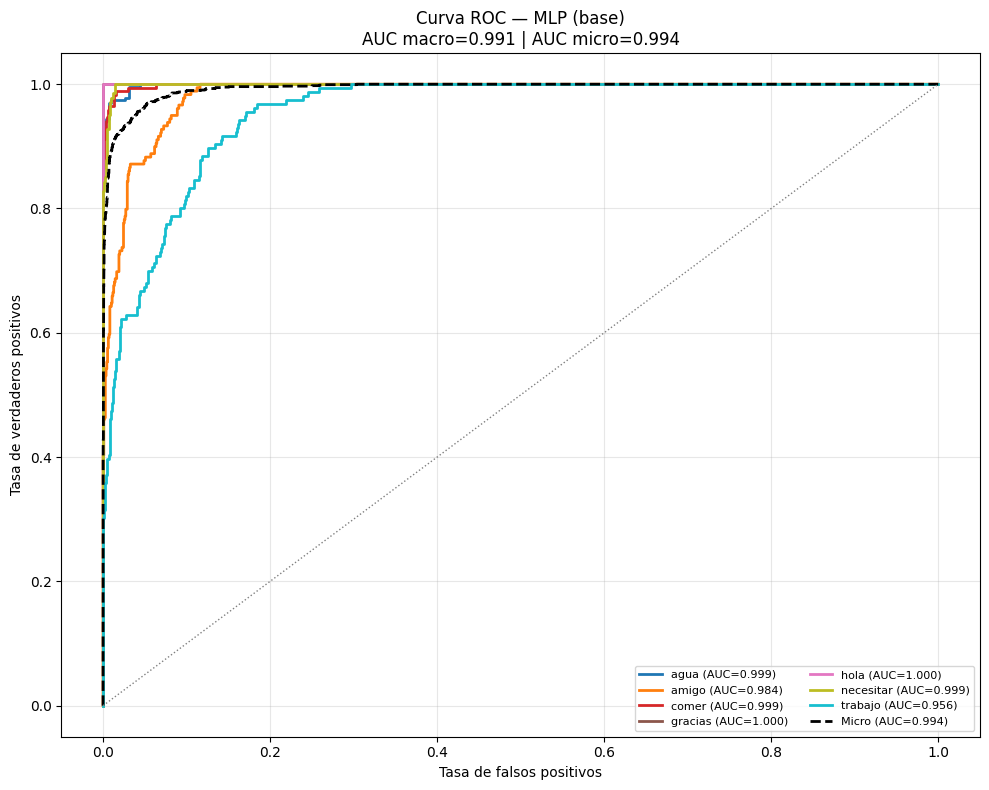

AUC macro: 0.9908 | AUC micro: 0.9936


In [ ]:
# -------------------- Curva ROC (uno contra el resto) --------------------
y_true = y_test_cmp
y_score = modelo_final_ensemble['y_proba']
if y_score is None:
    raise ValueError('El modelo final no expone predict_proba; no se puede graficar ROC/PR.')

clases = np.arange(len(le.classes_))
y_bin = label_binarize(y_true, classes=clases)
n_clases = y_bin.shape[1]
colores = plt.cm.tab10(np.linspace(0, 1, n_clases))

fig, ax = plt.subplots(figsize=(10, 8))
aucs = []
for i, color in zip(range(n_clases), colores):
    if y_bin[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f'{le.classes_[i]} (AUC={roc_auc:.3f})')
fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), y_score.ravel())
auc_micro = auc(fpr_micro, tpr_micro)
auc_macro = np.mean(aucs)
ax.plot(fpr_micro, tpr_micro, color='black', linestyle='--', lw=2,
        label=f'Micro (AUC={auc_micro:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1)
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos')
ax.set_title(f'Curva ROC — {nombre_modelo_final}\nAUC macro={auc_macro:.3f} | AUC micro={auc_micro:.3f}')
ax.legend(loc='lower right', fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'AUC macro: {auc_macro:.4f} | AUC micro: {auc_micro:.4f}')


### 9.2 Curva Precisión-Recall

La curva Precisión-Recall es más informativa que ROC cuando hay desbalance entre clases. El Average Precision (AP) resume la curva: valores cercanos a 1 indican que el modelo mantiene alta precisión a medida que aumenta el recall. Es especialmente útil para las clases con menos frames.


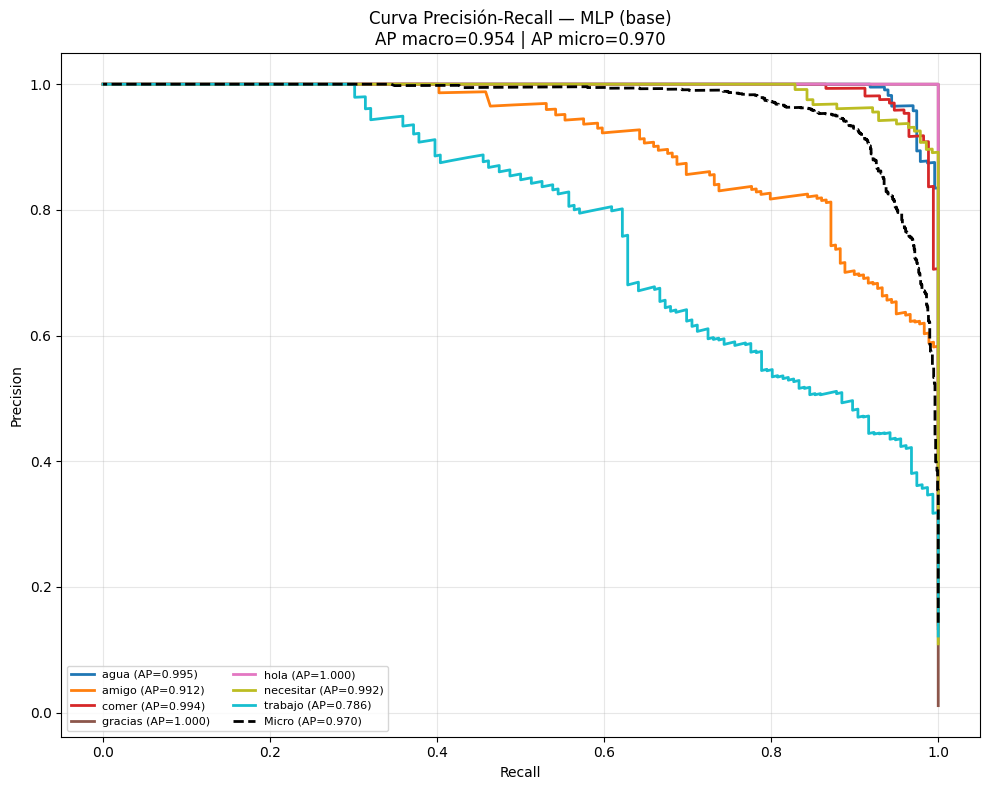

AP macro: 0.9540 | AP micro: 0.9704


In [ ]:
# -------------------- Curva Precisión-Recall (uno contra el resto) --------------------
y_true = y_test_cmp
y_score = modelo_final_ensemble['y_proba']
clases = np.arange(len(le.classes_))
y_bin = label_binarize(y_true, classes=clases)
n_clases = y_bin.shape[1]
colores = plt.cm.tab10(np.linspace(0, 1, n_clases))

fig, ax = plt.subplots(figsize=(10, 8))
aps = []
for i, color in zip(range(n_clases), colores):
    if y_bin[:, i].sum() == 0:
        continue
    precision, recall, _ = precision_recall_curve(y_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_bin[:, i], y_score[:, i])
    aps.append(ap)
    ax.plot(recall, precision, color=color, lw=2,
            label=f'{le.classes_[i]} (AP={ap:.3f})')
ap_macro = np.mean(aps)
precision_micro, recall_micro, _ = precision_recall_curve(y_bin.ravel(), y_score.ravel())
ap_micro = average_precision_score(y_bin.ravel(), y_score.ravel())
ax.plot(recall_micro, precision_micro, color='black', linestyle='--', lw=2,
        label=f'Micro (AP={ap_micro:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title(f'Curva Precisión-Recall — {nombre_modelo_final}\nAP macro={ap_macro:.3f} | AP micro={ap_micro:.3f}')
ax.legend(loc='lower left', fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'AP macro: {ap_macro:.4f} | AP micro: {ap_micro:.4f}')


### 9.3 Matriz de confusión

La diagonal muestra las predicciones correctas. Los valores fuera de la diagonal indican confusiones entre señas; los pares con más errores son los candidatos prioritarios para recolectar más datos o revisar la técnica de captura.


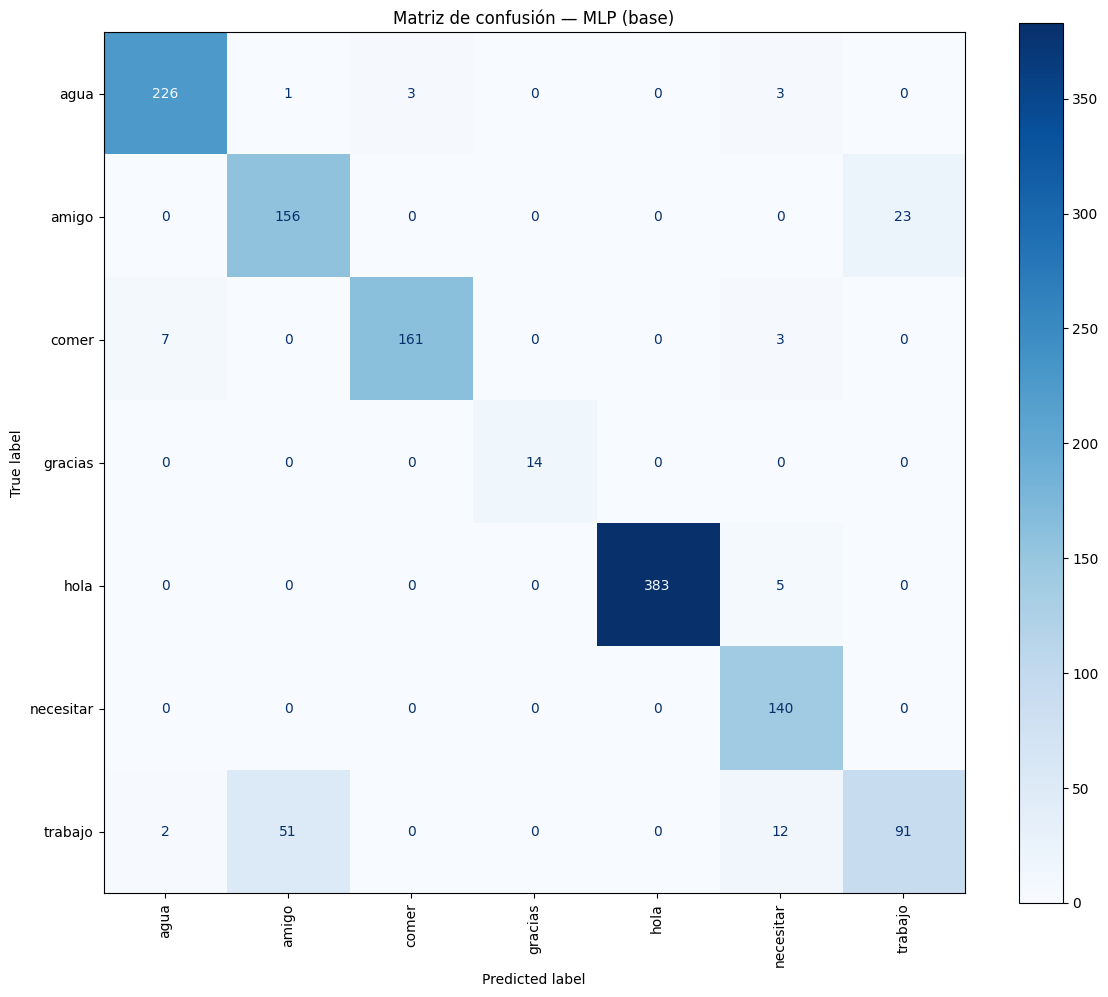

Pares más confundidos (real → predicho):
  trabajo → amigo: 51 frames
  amigo → trabajo: 23 frames
  trabajo → necesitar: 12 frames
  comer → agua: 7 frames
  hola → necesitar: 5 frames


In [ ]:
# -------------------- Matriz de confusión del modelo final --------------------
cm_final = confusion_matrix(y_test_cmp, modelo_final_ensemble['y_pred'],
                            labels=np.arange(len(le.classes_)))
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(cm_final, display_labels=le.classes_)
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=True)
plt.title(f'Matriz de confusión — {nombre_modelo_final}')
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

# Pares más confundidos (fuera de la diagonal)
confusiones = []
for i in range(len(le.classes_)):
    for j in range(len(le.classes_)):
        if i != j and cm_final[i, j] > 0:
            confusiones.append((cm_final[i, j], le.classes_[i], le.classes_[j]))
confusiones.sort(reverse=True, key=lambda x: x[0])
print('Pares más confundidos (real → predicho):')
for n, real, pred in confusiones[:5]:
    print(f'  {real} → {pred}: {n} frames')


### 9.4 Importancia de características

La importancia indica qué variables aportan más a la decisión del modelo. Si el modelo final es un ensamble heterogéneo, se usa la importancia del RF tuneado como componente interpretable. También se incluye un árbol de decisión superficial como apoyo visual; **no es el modelo final**, sino una aproximación para entender reglas simples.


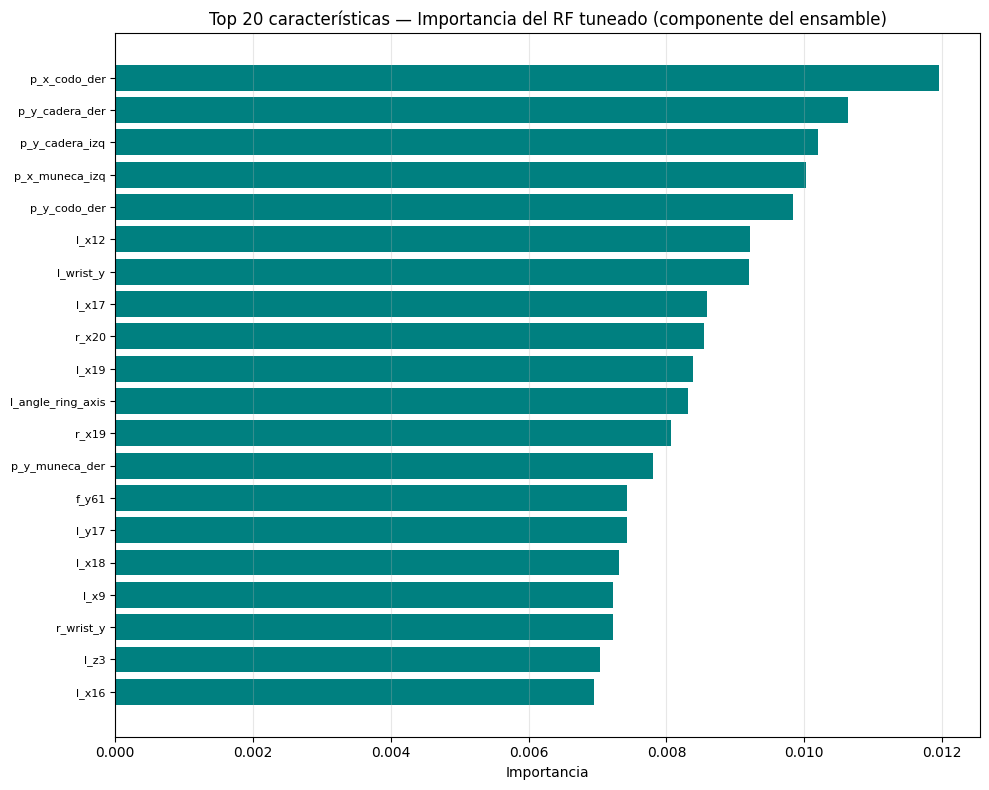

Método: Importancia del RF tuneado (componente del ensamble)
Top 10 características:
  p_x_codo_der: 0.0120
  p_y_cadera_der: 0.0106
  p_y_cadera_izq: 0.0102
  p_x_muneca_izq: 0.0100
  p_y_codo_der: 0.0098
  l_x12: 0.0092
  l_wrist_y: 0.0092
  l_x17: 0.0086
  r_x20: 0.0085
  l_x19: 0.0084


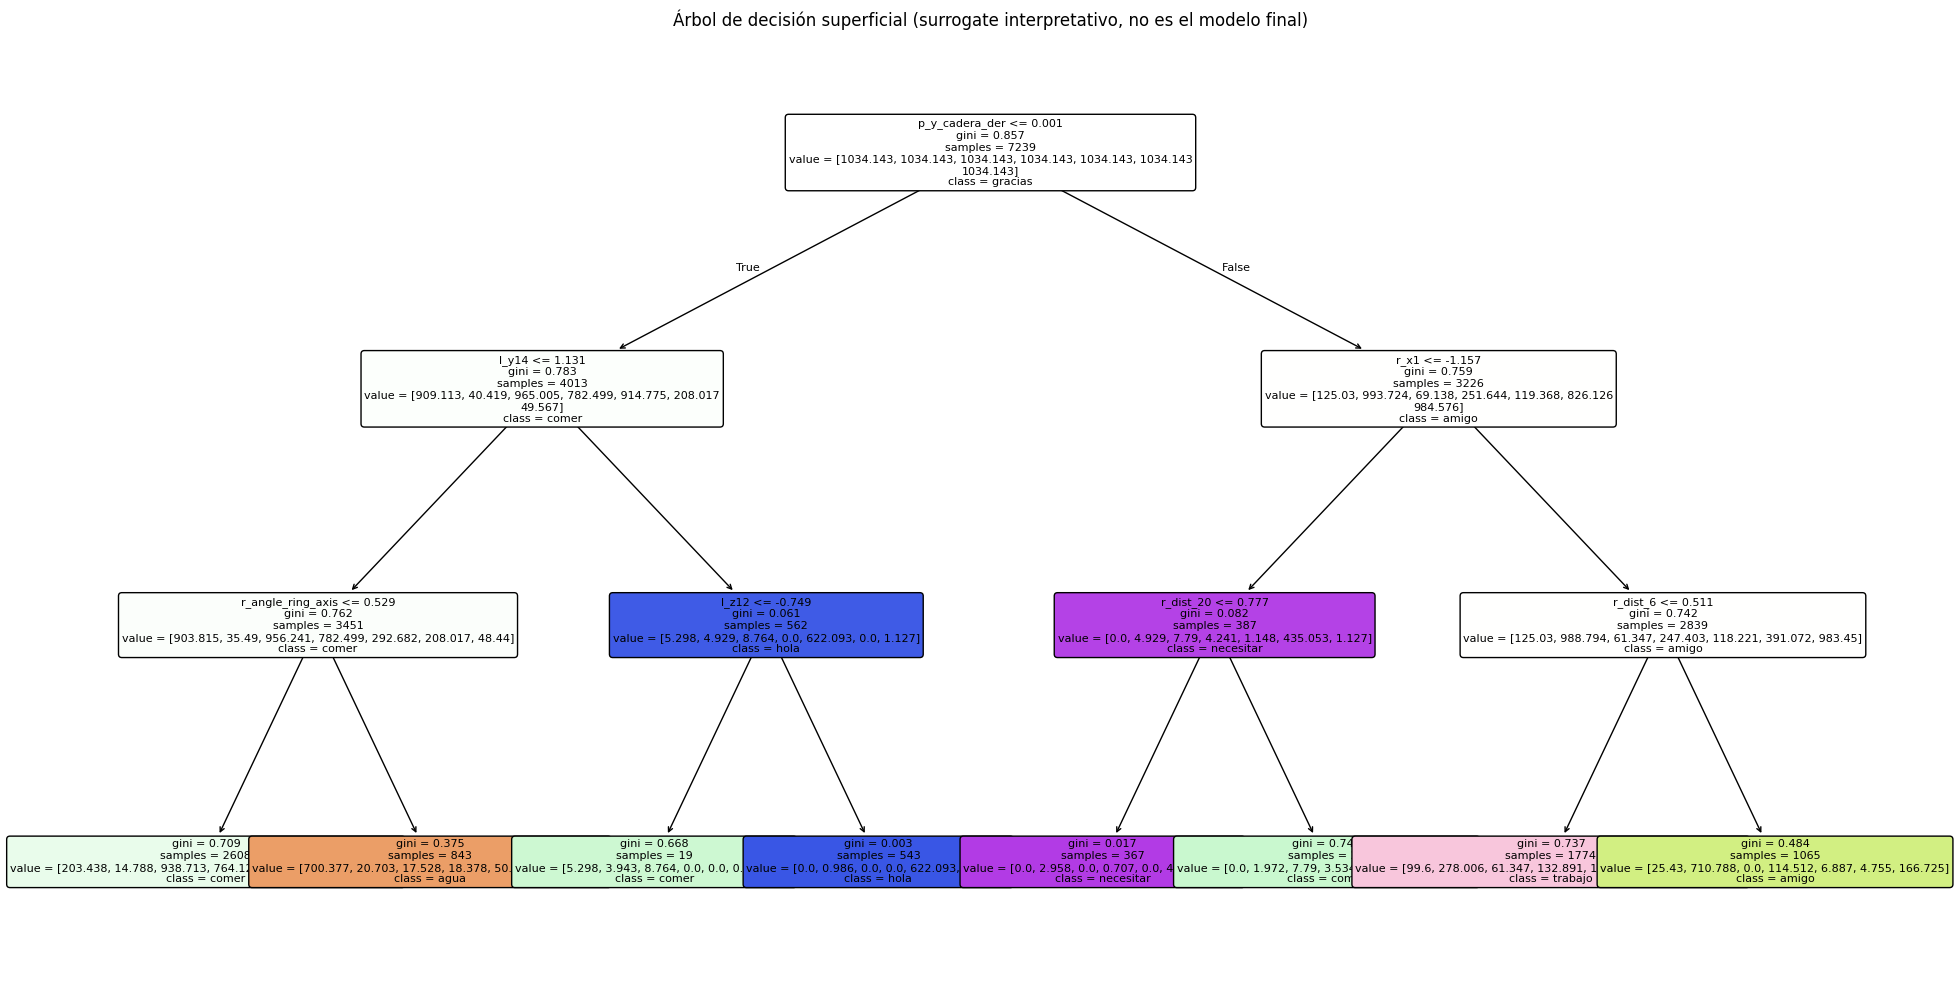

In [ ]:
# -------------------- Importancia de características --------------------
# Si el modelo final es un árbol/boosting, usamos su importancia nativa.
# Si es un ensamble heterogéneo, usamos la importancia del RF tuneado (componente del ensamble).
if hasattr(modelo_final_ensemble['modelo'], 'feature_importances_'):
    importancias = modelo_final_ensemble['modelo'].feature_importances_
    metodo_importancia = 'Importancia nativa del modelo final'
else:
    importancias = modelo_rf.feature_importances_
    metodo_importancia = 'Importancia del RF tuneado (componente del ensamble)'

orden = np.argsort(importancias)[::-1][:20]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(orden)), importancias[orden][::-1], color='teal')
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([feature_cols[i] for i in orden][::-1], fontsize=8)
ax.set_xlabel('Importancia')
ax.set_title(f'Top 20 características — {metodo_importancia}')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

print(f'Método: {metodo_importancia}')
print('Top 10 características:')
for i in orden[:10]:
    print(f'  {feature_cols[i]}: {importancias[i]:.4f}')

# Árbol de decisión superficial como apoyo interpretativo (surrogate)
arbol_surrogate = DecisionTreeClassifier(max_depth=3, random_state=42, class_weight='balanced')
arbol_surrogate.fit(X_train_s, y_train)
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(arbol_surrogate, feature_names=feature_cols,
          class_names=[str(c) for c in le.classes_],
          filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
plt.title('Árbol de decisión superficial (surrogate interpretativo, no es el modelo final)')
plt.tight_layout(); plt.show()


### 9.5 Comparación visual y tiempos

El gráfico compara el Macro-F1 y el tiempo de entrenamiento de todos los modelos. Un ensamble puede mejorar la métrica a costa de más tiempo de entrenamiento; para tiempo real importa sobre todo el tiempo de inferencia, que se reporta en la tabla.


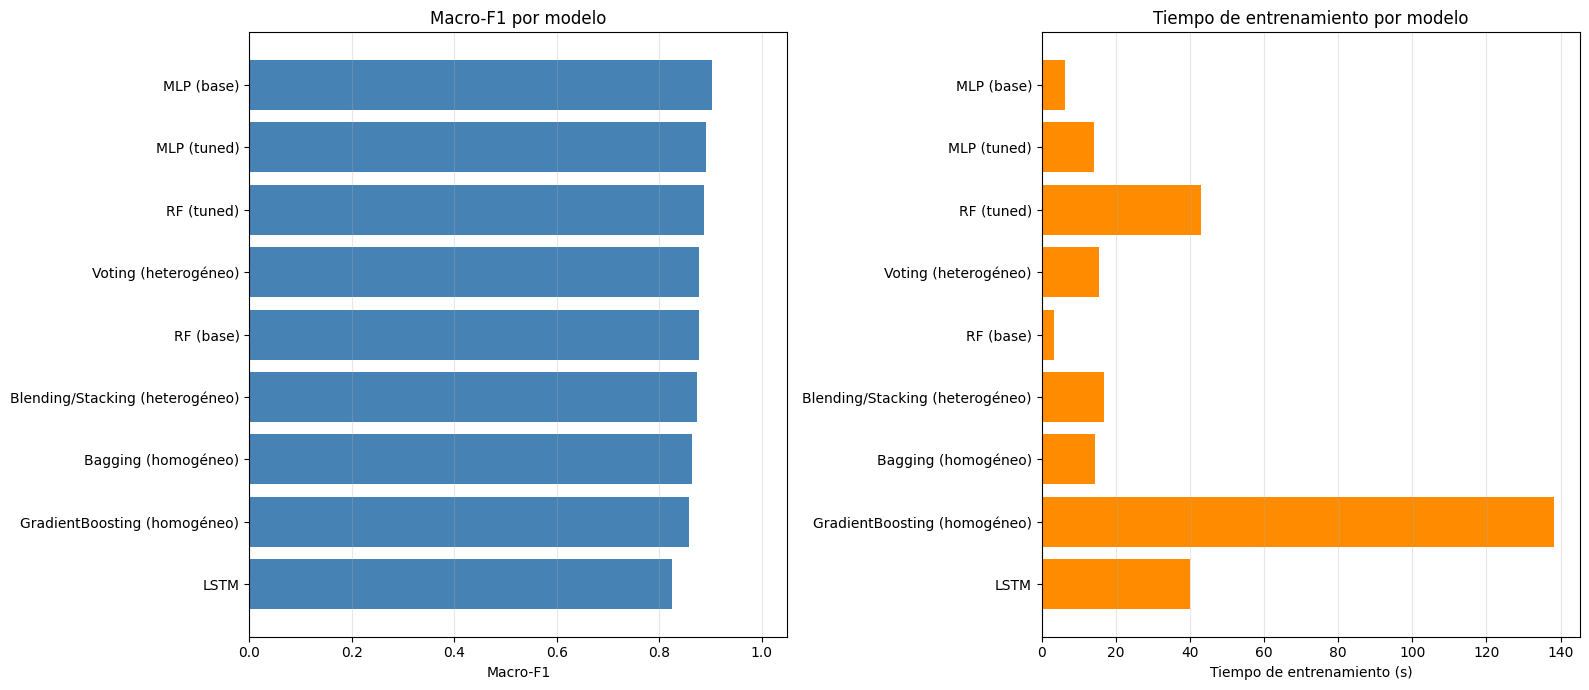

In [ ]:
# -------------------- Comparación visual de modelos --------------------
df_plot = df_resultados.copy()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(df_plot['Modelo'].values[::-1], df_plot['Macro-F1'].values[::-1], color='steelblue')
axes[0].set_xlabel('Macro-F1')
axes[0].set_title('Macro-F1 por modelo')
axes[0].set_xlim(0, 1.05)
axes[0].grid(axis='x', alpha=0.3)

axes[1].barh(df_plot['Modelo'].values[::-1],
             df_plot['Tiempo entrenamiento (s)'].values[::-1], color='darkorange')
axes[1].set_xlabel('Tiempo de entrenamiento (s)')
axes[1].set_title('Tiempo de entrenamiento por modelo')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout(); plt.show()


### 9.6 Interpretación y decisión

La interpretación automática resume las clases con menor recall, los pares más confundidos, las características más relevantes y la latencia. Con esa información se justifica el modelo final y se identifican acciones de mejora (más datos para ciertas clases, revisión de la segmentación de manos, etc.).


In [ ]:
# -------------------- Interpretación automática de resultados --------------------
reporte = classification_report(y_test_cmp, modelo_final_ensemble['y_pred'],
                                labels=np.arange(len(le.classes_)),
                                target_names=[str(c) for c in le.classes_],
                                output_dict=True, zero_division=0)
recalls = {c: reporte[str(c)]['recall'] for c in le.classes_}
clases_bajo_recall = sorted(recalls.items(), key=lambda x: x[1])[:3]

# Recalcular pares confundidos y top features si no existen en el entorno.
cm_tmp = confusion_matrix(y_test_cmp, modelo_final_ensemble['y_pred'],
                          labels=np.arange(len(le.classes_)))
confusiones = []
for i in range(len(le.classes_)):
    for j in range(len(le.classes_)):
        if i != j and cm_tmp[i, j] > 0:
            confusiones.append((cm_tmp[i, j], le.classes_[i], le.classes_[j]))
confusiones.sort(reverse=True, key=lambda x: x[0])
if 'orden' not in globals():
    orden = np.argsort(modelo_rf.feature_importances_)[::-1][:20]
top_features = [feature_cols[i] for i in orden[:5]]

if 'auc_macro' not in globals() or 'ap_macro' not in globals():
    y_bin_tmp = label_binarize(y_test_cmp, classes=np.arange(len(le.classes_)))
    aucs_tmp, aps_tmp = [], []
    for i in range(y_bin_tmp.shape[1]):
        if y_bin_tmp[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin_tmp[:, i], modelo_final_ensemble['y_proba'][:, i])
        aucs_tmp.append(auc(fpr, tpr))
        aps_tmp.append(average_precision_score(y_bin_tmp[:, i], modelo_final_ensemble['y_proba'][:, i]))
    auc_macro = np.mean(aucs_tmp)
    ap_macro = np.mean(aps_tmp)

print('INTERPRETACIÓN AUTOMÁTICA')
print(f'- Modelo final: {nombre_modelo_final}')
print(f'- Accuracy: {modelo_final_ensemble["Accuracy"]:.4f} | Macro-F1: {modelo_final_ensemble["Macro-F1"]:.4f}')
print(f'- Clases con menor recall: ' + ', '.join(f'{c} ({r:.3f})' for c, r in clases_bajo_recall))
print('- Pares más confundidos: ' + '; '.join(f'{real}→{pred} ({n})' for n, real, pred in confusiones[:3]))
print(f'- Top 5 características: ' + ', '.join(top_features))
print(f'- AUC macro: {auc_macro:.4f} | AP macro: {ap_macro:.4f}')
print(f'- Tiempo de entrenamiento: {modelo_final_ensemble["Tiempo entrenamiento (s)"]:.2f} s')
print(f'- Inferencia: {modelo_final_ensemble["Inferencia (ms/muestra)"]:.2f} ms/muestra')
print('\nLectura para entendimiento:')
print('- Un Macro-F1 alto indica buen desempeño promedio entre clases, no solo en las mayoritarias.')
print('- Las clases con menor recall son candidatas a más datos/variabilidad en la recolección.')
print('- La latencia debe mantenerse por debajo del umbral para que la detección sea en tiempo real.')
print('- El modelo final se guardó en RUTA_MODELO y es el que usa DetectorLSM en modo frame-level.')


INTERPRETACIÓN AUTOMÁTICA
- Modelo final: MLP (base)
- Accuracy: 0.9141 | Macro-F1: 0.9036
- Clases con menor recall: trabajo (0.583), amigo (0.872), comer (0.942)
- Pares más confundidos: trabajo→amigo (51); amigo→trabajo (23); trabajo→necesitar (12)
- Top 5 características: p_x_codo_der, p_y_cadera_der, p_y_cadera_izq, p_x_muneca_izq, p_y_codo_der
- AUC macro: 0.9908 | AP macro: 0.9540
- Tiempo de entrenamiento: 6.37 s
- Inferencia: 0.01 ms/muestra

Lectura para entendimiento:
- Un Macro-F1 alto indica buen desempeño promedio entre clases, no solo en las mayoritarias.
- Las clases con menor recall son candidatas a más datos/variabilidad en la recolección.
- La latencia debe mantenerse por debajo del umbral para que la detección sea en tiempo real.
- El modelo final se guardó en RUTA_MODELO y es el que usa DetectorLSM en modo frame-level.


## **10. Detección en tiempo real**


In [ ]:
# -------------------- Detector con suavizado --------------------
class DetectorLSM:
    def __init__(self, detectores=None, ventana=7, umbral=0.60, usar_lstm=False, modelo_lstm=None):
        self.det_manos, self.det_pose, self.det_cara = detectores or crear_detectores()
        self.usar_lstm = usar_lstm; self.umbral = umbral
        self.modelo_lstm = modelo_lstm
        # Si se usa LSTM, la ventana debe coincidir con la del modelo (p. ej. 15),
        # no con la ventana de suavizado de los modelos frame-level (p. ej. 7).
        self.ventana = getattr(modelo_lstm, 'ventana', ventana) if (usar_lstm and modelo_lstm is not None) else ventana
        self.historial = deque(maxlen=self.ventana)
        self.scaler = joblib.load(RUTA_SCALER) if os.path.exists(RUTA_SCALER) else None
        self.le = joblib.load(RUTA_ENCODER) if os.path.exists(RUTA_ENCODER) else None
        self.modelo_frame = joblib.load(RUTA_MODELO) if os.path.exists(RUTA_MODELO) else None

    def predecir_frame(self, frame):
        imagen_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_mp = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagen_rgb)
        res_manos = self.det_manos.detect(image_mp)
        res_pose  = self.det_pose.detect(image_mp)
        res_cara  = self.det_cara.detect(image_mp)
        vector, nm, np_, nc = vector_holistico(res_manos, res_pose, res_cara)
        dibujar_holistico(frame, res_manos, res_pose, res_cara)

        if nm == 0 and np_ == 0 and nc == 0:
            if self.usar_lstm:
                self.historial.clear()
            else:
                self.historial.append(None)
            return frame, '---', 0.0, 0, 0, 0

        if self.usar_lstm and self.modelo_lstm and self.scaler and self.le:
            self.historial.append(vector)
            if len(self.historial) < self.ventana:
                return frame, '---', 0.0, nm, np_, nc
            seq = np.array(list(self.historial), dtype=np.float32)
            seq_s = self.scaler.transform(seq.reshape(-1, seq.shape[-1])).reshape(1, self.ventana, -1)
            etiqueta, conf = self.modelo_lstm.predecir_secuencia(seq_s)
        else:
            modelo_frame = self.modelo_frame if self.modelo_frame is not None else modelo_final
            Xs = self.scaler.transform(vector.reshape(1,-1))
            etiqueta = self.le.inverse_transform([modelo_frame.predict(Xs)[0]])[0]
            conf = float(np.max(modelo_frame.predict_proba(Xs)[0])) if hasattr(modelo_frame,'predict_proba') else 1.0
            if conf >= self.umbral: self.historial.append(etiqueta)
            else: self.historial.append(None)
            votos = [v for v in self.historial if v is not None]
            etiqueta = Counter(votos).most_common(1)[0][0] if votos else '---'

        return frame, etiqueta, conf, nm, np_, nc


In [ ]:
def detectar_en_video(ruta_video, ventana=7, umbral=0.60, escalar=1.0, usar_lstm=False, modelo_lstm=None):
    det = DetectorLSM(ventana=ventana, umbral=umbral, usar_lstm=usar_lstm, modelo_lstm=modelo_lstm)
    cap = cv2.VideoCapture(ruta_video)
    nombre = os.path.splitext(os.path.basename(ruta_video))[0]
    if not cap.isOpened(): raise RuntimeError('No se pudo abrir el video')
    ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)*escalar); alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)*escalar)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    esc = cv2.VideoWriter_fourcc(*'mp4v'); wr = cv2.VideoWriter(f'videos_resultados/resultado_{nombre}.mp4', esc, fps, (ancho, alto))
    print('Procesando video...')
    while True:
        ret, frame = cap.read()
        if not ret: break
        if escalar != 1.0: frame = cv2.resize(frame, (ancho, alto))
        frame, etiqueta, conf, nm, np_, nc = det.predecir_frame(frame)
        cv2.rectangle(frame,(0,0),(ancho,120),(0,0,0),-1)
        cv2.putText(frame, f'Seña: {etiqueta}', (20,40), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0,255,0), 3)
        cv2.putText(frame, f'Conf: {conf:.2f} | M:{nm} P:{np_} C:{nc}', (20,80), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (200,200,200), 2)
        wr.write(frame)
    cap.release(); wr.release()
    print("Fin del procesamiento...")
    #print('Video guardado: resultado_lsm.mp4')
    #from google.colab import files; files.download('resultado_lsm.mp4')
    #print('Descargando resultado...')


In [ ]:
# -------------------- Prueba de detección en video --------------------
video = "videos_test/gracias02.mp4"
#video = "videos_lsm/hola/hola15.mp4"

# Cargar modelo LSTM con las rutas correctas de los archivos guardados
lstm = LSTMModeloLSM(modelo_ruta=RUTA_MODELO_LSTM,
                     scaler_ruta=RUTA_SCALER_LSTM,
                     encoder_ruta=RUTA_ENCODER_LSTM)
lstm.cargar()

detectar_en_video(
    ruta_video=video,
    ventana=lstm.ventana,      # Usa la ventana real del modelo
    umbral=0.90,
    escalar=1.0,
    usar_lstm=False,           # True para usar LSTM, False para usar RF/MLP
    modelo_lstm=lstm,          # Establecer configuracion para LSTM
)

W0000 00:00:1793662126.845568  136304 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793662126.857488  136304 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793662126.919404  136310 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793662127.025286  136309 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793662127.026885  136313 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1793662127.031626  136315 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. 

Detectores HandLandmarker, PoseLandmarker y FaceLandmarker creados.
Procesando video...
Fin del procesamiento...


## **11. Recomendaciones**

- **Datos:** 300-600 frames por clase, variedad de personas, ángulos e iluminación.
- **Evaluación:** usar split agrupado por video y macro-F1; evitar dividir frames al azar porque infla las métricas.
- **Ensambles:** comparar siempre contra los modelos individuales y reportar tiempos de entrenamiento e inferencia.
- **LSTM:** usar ventana de 15-30 frames para capturar movimiento y valida por video, no por ventana.
- **LSM:** valida con personas sordas o intérpretes certificados.
- **Ética:** no grabar sin consentimiento; no reemplaza a un intérprete.


## **Declaración sobre el uso de herramientas de inteligencia artificial**

*(Obligatoria. Sustituir este bloque por la plantilla de declaración en Markdown que adjunta la actividad en Experiencia 21, completándola con la información del equipo.)*

Información mínima a declarar:


*   Herramientas utilizadas (por ejemplo, GitHub Copilot en VS Code) y su versión o modelo.
*   Para qué se usaron: exploración del repositorio, diseño de la estructura de la libreta y generación de código base.
*   Qué validó el equipo: revisión del código, ejecución secuencial completa y verificación de los resultados.
*   Qué decisiones son responsabilidad del equipo: elección de modelos, métrica y justificación de conclusiones.